# **Proyecto – Tratamiento de Señales Discretas 2026-2 · Grupo 08**
## **Estimación de la frecuencia cardiaca a partir de 48 señales ECG contaminadas – Código final**

**Objetivo:** estimar la frecuencia cardiaca media de cada señal,
$$ FC = \frac{60}{\overline{RR}}\ \text{[lpm]}, $$
donde $\overline{RR}$ es el promedio (en segundos) de los intervalos entre latidos consecutivos en los 30 s de registro.

**Sistema que diseñé (una etapa por sección):**

| Etapa | Qué hago | Por qué |
|---|---|---|
| **1. Diagnóstico** | Cargo los datos, verifico $f_s$, calculo la FFT y mido red, deriva, EMG y aliasing | Para saber qué ruido tiene cada señal antes de procesar (detalle completo en `Etapa1_Diagnostico_Espectral.ipynb`) |
| **2. Preprocesamiento** | Filtro *notch* IIR en 60/120 Hz (o en el alias de 30 Hz si $f_s=90$ Hz) + pasa-banda Butterworth 5–15 Hz de fase cero | Quito la red y dejo solo la banda donde el QRS tiene más energía, eliminando a la vez la deriva (< 0.5 Hz) y gran parte del EMG |
| **3. Detección de picos R** | Algoritmo de Pan y Tompkins: derivada, cuadrado, integración en ventana móvil de 150 ms, umbrales adaptativos, periodo refractario, discriminación de onda T y *searchback* | Es un detector publicado, validado en la base MIT-BIH, robusto al ruido e insensible a la polaridad |
| **4. Cálculo de la FC** | $FC = 60/\overline{RR}$ y escribo `resultados_g08.csv` | Es la definición exigida en el enunciado |
| **5. Validación** | Reviso visualmente cada señal y comparo con un detector independiente (NeuroKit2) | Para detectar errores y analizar los casos más drásticos |

**Convención:** en el código escribo los comentarios en primera persona para explicar cada decisión.

## **1. Librerías y parámetros generales**

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import iirnotch, butter, filtfilt, freqz, find_peaks, medfilt

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

# Defino las rutas y constantes del proyecto en un solo lugar
CARPETA_DATOS = "data"                  # aquí están senal_01.csv ... senal_48.csv y LEEME.txt
ARCHIVO_RESULTADOS = "resultados_g08.csv"
F_RED = 60.0                            # en Colombia la red eléctrica es de 60 Hz (lo confirmé en la Etapa 1)

# Parámetros del preprocesamiento (justificados en la sección 3)
Q_NOTCH = 30.0                          # factor de calidad del notch: ancho de banda de -3 dB = f0/Q (2 Hz a 60 Hz)
BANDA_QRS = (5.0, 15.0)                 # banda pasante de Pan y Tompkins (1985)
ORDEN_BP = 2                            # orden del Butterworth (con filtfilt el orden efectivo es 4)

# Parámetros del detector (sección 4). Los de Pan y Tompkins los tomo del artículo original
VENTANA_MWI = 0.150                     # ventana de integración de 150 ms
REFRACTARIO = 0.200                     # 200 ms: ningún latido puede ocurrir antes (periodo refractario)
VENTANA_T = 0.360                       # entre 200 y 360 ms reviso si el pico es una onda T
FACTOR_SEARCHBACK = 1.66                # si pasa 1.66·RR medio sin latido, busco uno perdido con umbral menor

## **2. Carga de los datos y diagnóstico resumido (Etapa 1)**
### **2.1 Lectura de las señales**
Leo la frecuencia de muestreo del `LEEME.txt` y la verifico con el vector de tiempo ($f_s = 1/\Delta t$). La DFT y los filtros digitales suponen muestras equiespaciadas $x[n] = x_c(nT_s)$ (Oppenheim y Schafer, 2010, Sec. 4.1).

In [2]:
def leer_fs_leeme(ruta):
    # Leo las líneas del tipo 'senal_XX: YYY Hz' y armo un diccionario {numero: fs}
    fs = {}
    with open(ruta, encoding="utf-8", errors="ignore") as f:
        for linea in f:
            linea = linea.strip()
            if linea.startswith("senal_") and "Hz" in linea:
                nombre, resto = linea.split(":")
                fs[int(nombre.split("_")[1])] = float(resto.split("Hz")[0])
    return fs

def cargar_senales(carpeta):
    fs_leeme = leer_fs_leeme(os.path.join(carpeta, "LEEME.txt"))
    senales = {}
    for i in range(1, 49):
        df = pd.read_csv(os.path.join(carpeta, f"senal_{i:02d}.csv"))
        t = df["tiempo_s"].to_numpy()
        x = df["ecg_mV"].to_numpy(dtype=float)
        fs_t = 1.0 / np.median(np.diff(t))
        # Verifico que la fs del LEEME coincida con la del vector de tiempo y que no falten datos
        assert abs(fs_t - fs_leeme[i]) / fs_leeme[i] < 0.01, f"fs inconsistente en senal_{i:02d}"
        assert not np.isnan(x).any(), f"Hay NaN en senal_{i:02d}"
        senales[i] = {"t": t, "x": x, "fs": fs_leeme[i]}
    return senales

senales = cargar_senales(CARPETA_DATOS)
print("Señales cargadas:", len(senales))
print("Señales a 90 Hz:", [i for i, d in senales.items() if d["fs"] == 90])

Señales cargadas: 48
Señales a 90 Hz: [14, 23, 24, 34, 41]


### **2.2 Herramientas espectrales y diagnóstico de la red**
Calculo el espectro de magnitud con la FFT (Cooley y Tukey, 1965), restando la media y aplicando ventana de Hann para reducir la fuga espectral (Harris, 1978). La resolución es $\Delta f = f_s/N = 1/30\ \text{s} \approx 0.033$ Hz.

La frecuencia **aparente** de la red depende de $f_s$. Por el teorema de muestreo, una sinusoide de frecuencia $f_0 > f_s/2$ aparece en
$$ f_a = \left| f_0 - k f_s \right|, \quad k = \operatorname{round}(f_0/f_s) $$
(Proakis y Manolakis, 2007, Sec. 1.4.1; Oppenheim y Schafer, 2010, Sec. 4.2). Con $f_s = 90$ Hz: $60 \rightarrow 30$ Hz, $120 \rightarrow 30$ Hz y $180 \rightarrow 0$ Hz. En la Etapa 1 demostré que las 5 señales de 90 Hz tienen un tono de 0.33–1.14 mV en exactamente 30 Hz.

In [3]:
def espectro_magnitud(x, fs):
    # Resto la media, aplico Hann y normalizo para leer la amplitud directamente en mV
    w = np.hanning(len(x))
    X = np.fft.rfft((x - np.mean(x)) * w)
    f = np.fft.rfftfreq(len(x), 1.0 / fs)
    return f, 2.0 * np.abs(X) / w.sum()

def frecuencia_alias(f0, fs):
    # Aplico f_a = |f0 - k·fs| con k = round(f0/fs)
    return abs(f0 - fs * np.round(f0 / fs))

def frecuencias_red(fs):
    # Devuelvo dónde aparecen 60, 120 y 180 Hz dentro de (0, fs/2) para esta fs.
    # Descarto las que caen en DC (ya la quito con la media y el pasa-banda) o pegadas a Nyquist.
    fr = []
    for h in (F_RED, 2 * F_RED, 3 * F_RED):
        fa = h if h < fs / 2 else frecuencia_alias(h, fs)
        if 1.0 < fa < fs / 2 - 1.0 and all(abs(fa - g) > 0.5 for g in fr):
            fr.append(fa)
    return fr

def snr_tono_db(f, mag, f0):
    # Comparo el pico en f0 con la mediana de su vecindad (1–5 Hz alrededor)
    pico = mag[np.abs(f - f0) <= 0.5].max()
    vecindad = mag[(np.abs(f - f0) > 1) & (np.abs(f - f0) < 5)]
    return 20 * np.log10(pico / np.median(vecindad))

filas = []
for i, d in senales.items():
    f, mag = espectro_magnitud(d["x"], d["fs"])
    f_red = frecuencias_red(d["fs"])[0]
    filas.append({"senal": i, "fs": int(d["fs"]), "f_red_aparente_Hz": f_red,
                  "amp_red_mV": round(mag[np.abs(f - f_red) <= 0.5].max(), 3),
                  "SNR_red_dB": round(snr_tono_db(f, mag, f_red), 1)})
diag = pd.DataFrame(filas).set_index("senal")
diag.T

senal,1,2,3,4,5,6,7,8,9,10,...,39,40,41,42,43,44,45,46,47,48
fs,360.000,360.000,360.00,360.000,360.000,360.000,360.000,360.000,360.000,360.000,...,360.000,360.000,90.000,360.000,360.000,360.000,360.000,360.000,360.0,360.000
f_red_aparente_Hz,60.000,60.000,60.00,60.000,60.000,60.000,60.000,60.000,60.000,60.000,...,60.000,60.000,30.000,60.000,60.000,60.000,60.000,60.000,60.0,60.000
amp_red_mV,0.011,0.292,0.33,1.102,0.536,0.001,0.945,1.277,0.601,0.001,...,0.008,0.862,0.618,0.001,0.008,1.439,0.001,0.008,0.0,0.009
SNR_red_dB,22.000,54.600,55.50,70.600,57.600,10.500,50.100,59.100,64.900,6.000,...,27.100,63.100,46.500,9.800,16.600,64.600,7.000,15.200,5.2,23.200


## **3. Etapa 2 – Preprocesamiento**
### **3.1 Filtro notch IIR para la interferencia de red**
**Qué es:** un filtro de segundo orden con un par de **ceros sobre el círculo unitario** en $z = e^{\pm j\omega_0}$ (anula exactamente $f_0$) y un par de **polos muy cerca de esos ceros**, en $z = r e^{\pm j\omega_0}$ con $r \lesssim 1$, que hacen que la respuesta vuelva a ≈ 1 apenas me alejo de $f_0$:
$$ H(z) = \frac{1 - 2\cos\omega_0\, z^{-1} + z^{-2}}{1 - 2r\cos\omega_0\, z^{-1} + r^2 z^{-2}}, \qquad \omega_0 = 2\pi\frac{f_0}{f_s} $$
(Proakis y Manolakis, 2007, Sec. 5.4, filtros notch; Oppenheim y Schafer, 2010, Cap. 5, relación entre polos/ceros y respuesta en frecuencia). `scipy.signal.iirnotch` diseña este filtro a partir de $f_0$ y del factor de calidad $Q = f_0/\text{BW}_{-3\,dB}$.

**Por qué lo uso aquí:**
- La Etapa 1 mostró que la red es una **línea angosta y estacionaria** (amplitud constante en todo el registro) de hasta 1.4 mV, con armónico en 120 Hz. Un notch elimina exactamente esa línea y deja casi intacto el resto del espectro.
- Con $Q = 30$ el ancho de banda eliminado es de 2 Hz en 60 Hz (1 Hz en 30 Hz), es decir, el filtro afecta una porción despreciable del ECG.
- En las señales de 90 Hz el notch va en **30 Hz**, porque ahí quedó la red tras el aliasing. Usar 60 Hz no serviría de nada: a 90 Hz de muestreo esa frecuencia ni siquiera existe en el rango $[0, 45]$ Hz.
- El pasa-banda 5–15 Hz ya atenúa la red (≈ 50 dB a 30 Hz con $f_s=90$ y ≈ 65 dB a 60 Hz con $f_s=360$, ver sección 3.5). Aun así uso el notch por dos razones: (i) la señal de visualización (hasta 40 Hz), con la que mido la amplitud de cada latido, conserva la red si no la quito; (ii) con tonos de hasta 1.4 mV prefiero eliminar la línea en su origen y no depender solo de la atenuación del pasa-banda.
- Hamilton (1996) comparó filtros notch fijos y adaptativos para la red en ECG; con interferencia de frecuencia estable, como la de estos datos, el notch fijo es adecuado.

### **3.2 Filtrado de fase cero (`filtfilt`)**
Un filtro IIR tiene fase no lineal, así que distorsiona y **retrasa** el QRS. Al filtrar hacia adelante y luego hacia atrás, la respuesta total es $|H(e^{j\omega})|^2$ con **fase cero**, de modo que los picos R no se desplazan en el tiempo (Oppenheim y Schafer, 2010, Cap. 5; Gustafsson, 1996, para el manejo de las condiciones iniciales que usa `filtfilt`). Esto es importante porque mido tiempos (intervalos RR). Como el procesamiento es fuera de línea (tengo los 30 s completos), filtrar en ambos sentidos no plantea problemas de causalidad.

### **3.3 Pasa-banda Butterworth 5–15 Hz**
**Por qué esa banda:**
- La energía del complejo QRS se concentra aproximadamente entre 5 y 15 Hz (Thakor, Webster y Tompkins, 1984). Pan y Tompkins (1985) usan precisamente la banda 5–15 Hz para maximizar la energía del QRS frente a la onda T, la onda P, la deriva y el ruido muscular.
- **Deriva de línea base (< 0.5 Hz):** queda en la banda de rechazo. No necesito un filtro de deriva aparte para detectar.
- **Ruido muscular (EMG, banda ancha > 20–40 Hz):** se atenúa con el corte superior.
- **Señales de 90 Hz:** la banda 5–15 Hz está muy por debajo de Nyquist (45 Hz), así que el mismo diseño sirve para las dos frecuencias de muestreo (normalizo los cortes con $f_s/2$).

**Por qué Butterworth:** es máximamente plano en la banda pasante (no tiene rizado que deforme la amplitud del QRS) (Oppenheim y Schafer, 2010, Cap. 7, diseño de filtros IIR a partir de prototipos analógicos).

### **3.4 Señal para visualización (no se usa para detectar)**
Para ver la morfología limpia en las gráficas quito la línea base con dos filtros de mediana en cascada de 200 ms y 600 ms (de Chazal, O'Dwyer y Reilly, 2004) y luego aplico un pasa-bajos de 40 Hz. Esta señal solo sirve para graficar y para medir la amplitud local de cada detección.

In [4]:
def aplicar_notch_red(x, fs):
    # Aplico un notch IIR (fase cero) en cada frecuencia aparente de la red para esta fs
    y = x.copy()
    for f0 in frecuencias_red(fs):
        b, a = iirnotch(f0, Q_NOTCH, fs)
        y = filtfilt(b, a, y)
    return y

def pasa_banda(x, fs, f1, f2, orden=ORDEN_BP):
    # Diseño un Butterworth pasa-banda y lo aplico ida y vuelta para no desplazar los picos R
    b, a = butter(orden, [f1 / (fs / 2), f2 / (fs / 2)], btype="band")
    return filtfilt(b, a, x)

def quitar_linea_base(x, fs):
    # Estimo la línea base con dos medianas (200 ms quita el QRS, 600 ms quita P y T) y la resto
    w1 = int(0.2 * fs) | 1                 # fuerzo longitud impar
    w2 = int(0.6 * fs) | 1
    return x - medfilt(medfilt(x, w1), w2)

def preprocesar(x, fs):
    # Encadeno: quitar media -> notch de red -> (a) pasa-banda 5–15 Hz para detectar, (b) señal limpia para ver
    x0 = x - np.mean(x)
    x_notch = aplicar_notch_red(x0, fs)
    x_qrs = pasa_banda(x_notch, fs, *BANDA_QRS)
    b, a = butter(2, min(40.0, fs / 2 - 3) / (fs / 2), btype="low")
    x_vista = filtfilt(b, a, quitar_linea_base(x_notch, fs))
    return {"notch": x_notch, "qrs": x_qrs, "vista": x_vista}

### **3.5 Respuesta en frecuencia de los filtros que diseñé**
Grafico $|H(e^{j\omega})|^2$ (la respuesta efectiva tras `filtfilt`) para las dos frecuencias de muestreo.

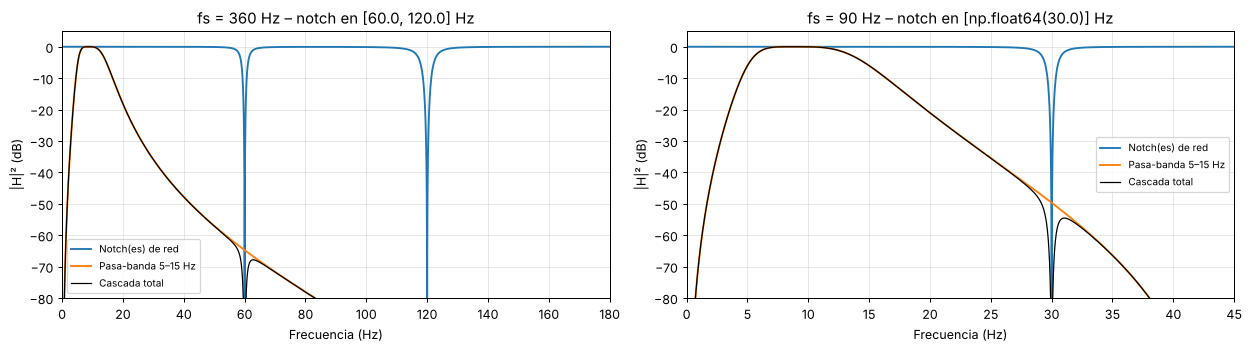

fs=360 Hz, pasa-banda solo, f=  0.3 Hz:  -111.7 dB
fs=360 Hz, pasa-banda solo, f= 10.0 Hz:    -0.0 dB
fs=360 Hz, pasa-banda solo, f= 30.0 Hz:   -35.9 dB
fs=360 Hz, pasa-banda solo, f= 60.0 Hz:   -64.8 dB
fs=90 Hz, pasa-banda solo, f=  0.3 Hz:  -110.7 dB
fs=90 Hz, pasa-banda solo, f= 10.0 Hz:    -0.0 dB
fs=90 Hz, pasa-banda solo, f= 30.0 Hz:   -49.7 dB


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for k, fs in enumerate((360.0, 90.0)):
    w = np.linspace(0, fs / 2, 4000)
    H = np.ones_like(w, dtype=complex)
    for f0 in frecuencias_red(fs):
        b, a = iirnotch(f0, Q_NOTCH, fs)
        H *= freqz(b, a, worN=w, fs=fs)[1]
    b, a = butter(ORDEN_BP, [BANDA_QRS[0] / (fs / 2), BANDA_QRS[1] / (fs / 2)], btype="band")
    Hbp = freqz(b, a, worN=w, fs=fs)[1]
    ax[k].plot(w, 20 * np.log10(np.abs(H) ** 2 + 1e-12), label="Notch(es) de red")
    ax[k].plot(w, 20 * np.log10(np.abs(Hbp) ** 2 + 1e-12), label="Pasa-banda 5–15 Hz")
    ax[k].plot(w, 20 * np.log10(np.abs(H * Hbp) ** 2 + 1e-12), "k", lw=1, label="Cascada total")
    ax[k].set(title=f"fs = {fs:.0f} Hz – notch en {frecuencias_red(fs)} Hz", xlabel="Frecuencia (Hz)",
              ylabel="|H|² (dB)", ylim=(-80, 5), xlim=(0, fs / 2))
    ax[k].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Imprimo la atenuación de la cascada en las frecuencias que me interesan
for fs in (360.0, 90.0):
    b, a = butter(ORDEN_BP, [BANDA_QRS[0] / (fs / 2), BANDA_QRS[1] / (fs / 2)], btype="band")
    for f_eval in (0.3, 10.0, 30.0, 60.0):
        if f_eval < fs / 2:
            g = np.abs(freqz(b, a, worN=[f_eval], fs=fs)[1][0]) ** 2
            print(f"fs={fs:.0f} Hz, pasa-banda solo, f={f_eval:5.1f} Hz: {20*np.log10(g):7.1f} dB")

### **3.6 Efecto del preprocesamiento en el tiempo y en la frecuencia**
Muestro cuatro casos representativos: red muy fuerte (04), una señal de 90 Hz con alias (24), deriva fuerte (17) y EMG (07).

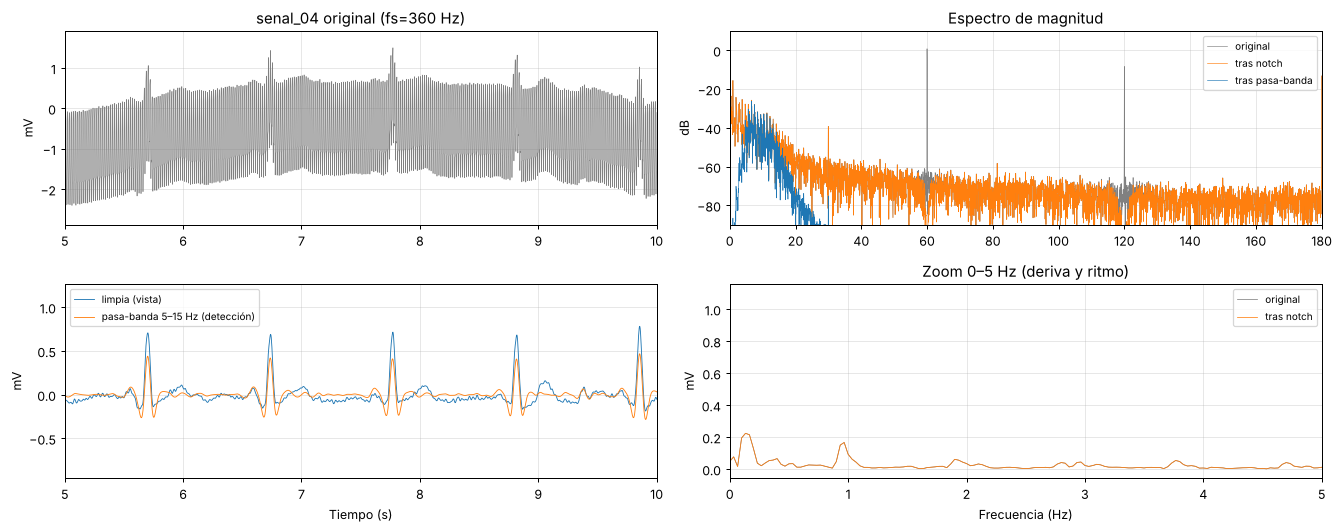

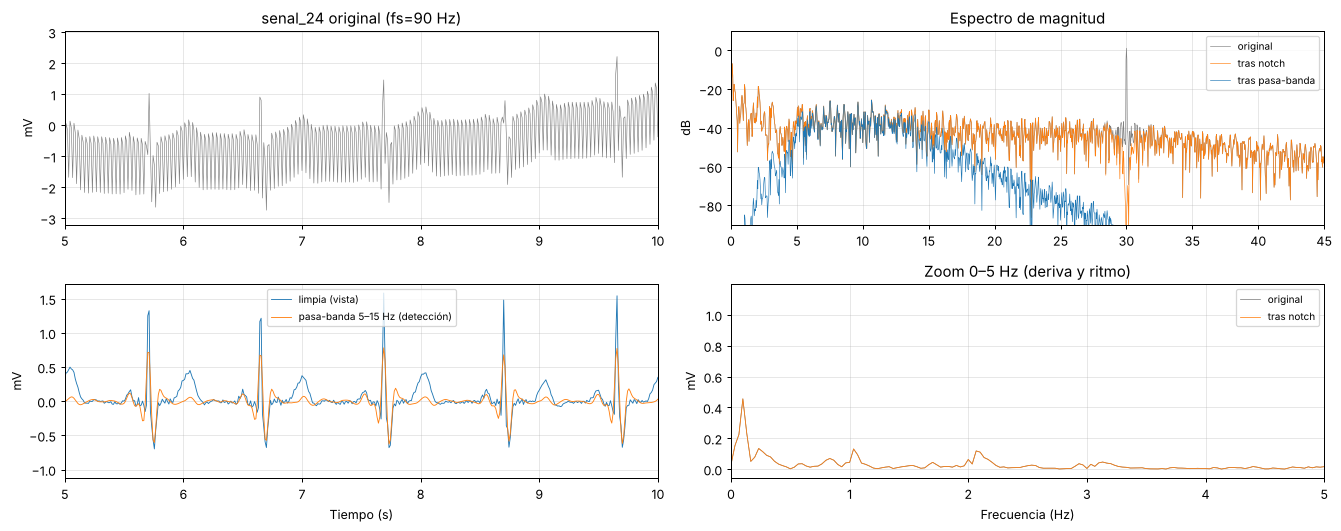

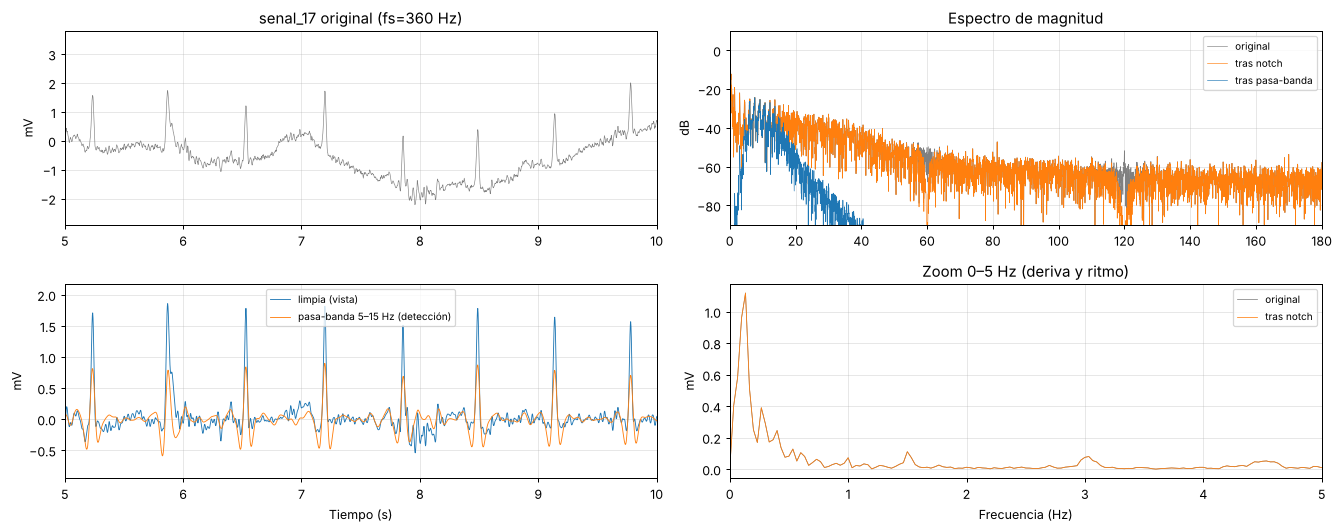

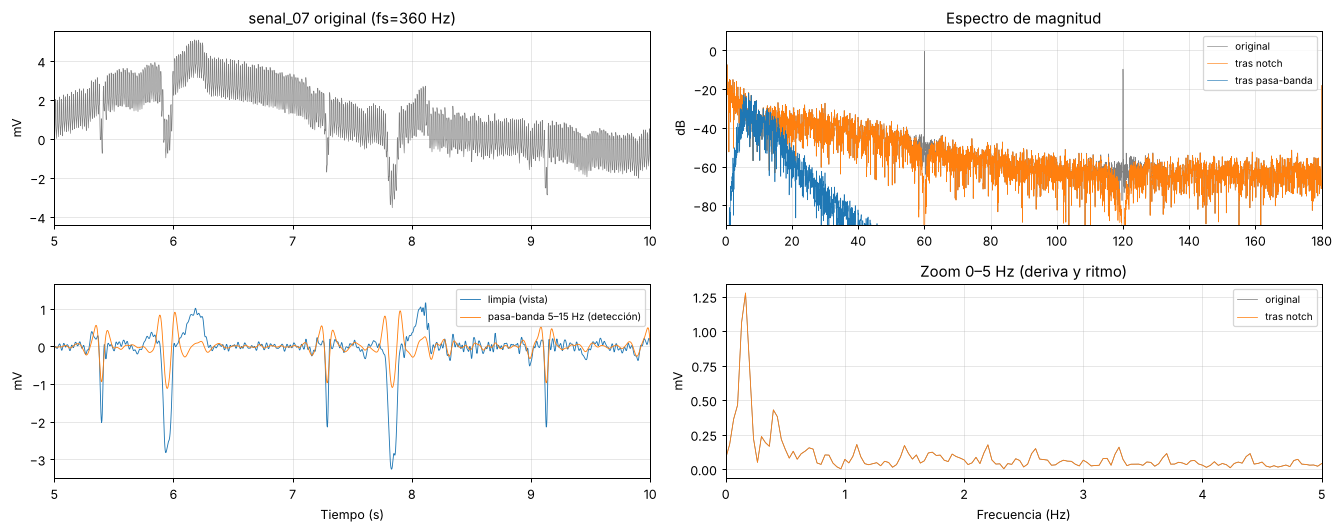

In [6]:
for i in (4, 24, 17, 7):
    d = senales[i]; fs = d["fs"]; t = d["t"]
    p = preprocesar(d["x"], fs)
    fig, ax = plt.subplots(2, 2, figsize=(15, 6))
    ax[0, 0].plot(t, d["x"], lw=0.5, color="gray"); ax[0, 0].set(title=f"senal_{i:02d} original (fs={fs:.0f} Hz)", xlim=(5, 10), ylabel="mV")
    ax[1, 0].plot(t, p["vista"], lw=0.7, label="limpia (vista)")
    ax[1, 0].plot(t, p["qrs"], lw=0.7, label="pasa-banda 5–15 Hz (detección)")
    ax[1, 0].set(xlim=(5, 10), xlabel="Tiempo (s)", ylabel="mV"); ax[1, 0].legend(fontsize=8)
    for sig, lab, c in ((d["x"], "original", "gray"), (p["notch"], "tras notch", "tab:orange"), (p["qrs"], "tras pasa-banda", "tab:blue")):
        f, mag = espectro_magnitud(sig, fs)
        ax[0, 1].plot(f, 20 * np.log10(mag + 1e-12), lw=0.5, color=c, label=lab)
    ax[0, 1].set(title="Espectro de magnitud", xlim=(0, fs / 2), ylim=(-90, 10), ylabel="dB"); ax[0, 1].legend(fontsize=8)
    f, mag = espectro_magnitud(d["x"], fs); f2, mag2 = espectro_magnitud(p["notch"], fs)
    ax[1, 1].plot(f, mag, color="gray", lw=0.6, label="original"); ax[1, 1].plot(f2, mag2, color="tab:orange", lw=0.6, label="tras notch")
    ax[1, 1].set(title="Zoom 0–5 Hz (deriva y ritmo)", xlim=(0, 5), xlabel="Frecuencia (Hz)", ylabel="mV"); ax[1, 1].legend(fontsize=8)
    plt.tight_layout(); plt.show()

## **4. Etapa 3 – Detección de picos R (algoritmo de Pan y Tompkins)**
### **4.1 Cadena de transformaciones**
Sobre la señal pasa-banda $x_{bp}[n]$ aplico (Pan y Tompkins, 1985):
1. **Derivada:** $\;y_d[n] = \dfrac{x_{bp}[n+1]-x_{bp}[n-1]}{2T_s}$. Resalta las pendientes altas, que son propias del QRS y no de las ondas P y T.
2. **Cuadrado:** $\;y_c[n] = y_d^2[n]$. Vuelve todo positivo, de modo que el detector funciona **igual con QRS positivos o negativos** (en los datos hay señales con polaridad invertida, como la 06, la 07, la 39 o la 44). Además, el cuadrado amplifica de forma no lineal las pendientes grandes del QRS frente a las pequeñas del ruido.
3. **Integración en ventana móvil (MWI)** de $N_w = 0.150 f_s$ muestras: $\;y_i[n] = \dfrac{1}{N_w}\sum_{m=0}^{N_w-1} y_c[n-m]$. Produce un pulso por cada QRS. La ventana de 150 ms es del orden de la duración del QRS más ancho.

### **4.2 Reglas de decisión del artículo original**
- **Umbrales adaptativos:** mantengo una estimación del nivel de los picos de señal ($SPKI$) y de los de ruido ($NPKI$), que actualizo con un promedio exponencial: $SPKI \leftarrow 0.125\,PEAKI + 0.875\,SPKI$ (igual para $NPKI$). El umbral es $\;THR = NPKI + 0.25\,(SPKI - NPKI)$. Así el detector **se adapta** a los cambios de amplitud producidos por la deriva, el movimiento o la morfología.
- **Periodo refractario de 200 ms:** dos QRS no pueden estar a menos de 200 ms (equivaldría a 300 lpm).
- **Discriminación de onda T:** si un candidato aparece entre 200 y 360 ms después del latido anterior y su pendiente máxima es menor que la mitad de la del latido anterior, lo considero una onda T.
- **Searchback:** si pasan más de $1.66\cdot\overline{RR}_{8}$ (el promedio de los últimos 8 RR) sin latido, busco hacia atrás el pico más alto que supere la mitad del umbral, porque probablemente perdí un latido de baja amplitud.

### **4.3 Ajustes propios (heurísticas del grupo, no del artículo)**
- Descarto detecciones en los primeros y últimos 100 ms, donde `filtfilt` tiene efectos de borde.
- Si dos detecciones están a menos de 0.3 s (más de 200 lpm), o a menos de 0.6 veces la mediana del RR **y** una de ellas tiene una amplitud local menor que el 35 % de la típica, elimino la más débil. Así quito artefactos sin borrar extrasístoles, que son prematuras pero **grandes**.
- Hago un *searchback* final en todo el registro con el RR mediano, que es robusto frente a extrasístoles.
- Ubico el pico R exacto como el máximo de $|x_{bp}|$ en ±50 ms alrededor del pico de la MWI, porque la integración introduce un retardo de aproximadamente media ventana.

In [7]:
def pan_tompkins(x_bp, fs):
    # 1) Derivada (diferencia central) y 2) cuadrado
    deriv = np.gradient(x_bp) * fs
    cuad = deriv ** 2
    # 3) Integro en una ventana móvil de 150 ms
    nw = int(round(VENTANA_MWI * fs))
    mwi = np.convolve(cuad, np.ones(nw) / nw, mode="same")

    # Busco todos los picos de la MWI respetando el periodo refractario
    picos, _ = find_peaks(mwi, distance=int(REFRACTARIO * fs))

    # Inicializo los niveles de señal y de ruido con los primeros 2 s (fase de aprendizaje del artículo)
    ini = mwi[: int(2 * fs)]
    spki, npki = 0.25 * ini.max(), 0.5 * ini.mean()
    umbral = npki + 0.25 * (spki - npki)
    r = []
    for p in picos:
        if mwi[p] > umbral:
            # Si está entre 200 y 360 ms del latido anterior, reviso si es una onda T comparando pendientes
            if r and (p - r[-1]) < VENTANA_T * fs:
                pend_act = np.max(np.abs(deriv[max(0, p - nw): p + 1]))
                pend_ant = np.max(np.abs(deriv[max(0, r[-1] - nw): r[-1] + 1]))
                if pend_act < 0.5 * pend_ant:
                    npki = 0.125 * mwi[p] + 0.875 * npki       # la trato como ruido
                    umbral = npki + 0.25 * (spki - npki)
                    continue
            r.append(p)
            spki = 0.125 * mwi[p] + 0.875 * spki
        else:
            npki = 0.125 * mwi[p] + 0.875 * npki
        umbral = npki + 0.25 * (spki - npki)

        # Searchback: si llevo mucho tiempo sin latido, busco el pico perdido con la mitad del umbral
        if len(r) >= 9:
            rr_medio = np.mean(np.diff(r[-9:]))
            if p - r[-1] > FACTOR_SEARCHBACK * rr_medio:
                cand = [q for q in picos if r[-1] + REFRACTARIO * fs < q < p and mwi[q] > 0.5 * umbral]
                if cand:
                    q = max(cand, key=lambda q: mwi[q])
                    r.append(q); r.sort()
                    spki = 0.25 * mwi[q] + 0.75 * spki
    return np.array(sorted(set(r)), dtype=int), mwi


def depurar_detecciones(r, mwi, x_vista, fs):
    # Aplico mis reglas adicionales (sección 4.3) y dejo un registro de lo que cambio
    registro = []
    w = int(0.06 * fs)
    amp_local = lambda p: np.ptp(x_vista[max(0, p - w): p + w])
    r = [int(p) for p in r if 0.1 * fs < p < len(mwi) - 0.1 * fs]      # quito los bordes

    # (a) Elimino detecciones demasiado cercanas que además son débiles
    cambio = True
    while cambio and len(r) > 3:
        cambio = False
        rr = np.diff(r); med = np.median(rr)
        amp_tip = np.median([amp_local(p) for p in r])
        for k in np.where(rr < max(0.3 * fs, 0.6 * med))[0]:
            if rr[k] < 0.3 * fs:
                cand = [k, k + 1]                                         # > 200 lpm: uno de los dos sobra
            else:
                cand = [j for j in (k, k + 1) if amp_local(r[j]) < 0.35 * amp_tip]
            if cand:
                j = min(cand, key=lambda j: mwi[r[j]])
                registro.append(("eliminado", round(r[j] / fs, 2)))
                r.pop(j); cambio = True
                break

    # (b) Searchback global con el RR mediano
    picos, _ = find_peaks(mwi, distance=int(REFRACTARIO * fs))
    cambio = True
    while cambio and len(r) > 3:
        cambio = False
        rr = np.diff(r); med = np.median(rr); nivel = np.median(mwi[r])
        for k in np.where(rr > 1.6 * med)[0]:
            a, b = r[k], r[k + 1]
            cand = [q for q in picos if a + 0.35 * med < q < b - 0.35 * med and mwi[q] > 0.4 * nivel]
            if cand:
                q = max(cand, key=lambda q: mwi[q])
                r.insert(k + 1, int(q)); registro.append(("agregado", round(q / fs, 2)))
                cambio = True
                break
    return np.array(r, dtype=int), registro


def ubicar_pico_r(r, x_bp, fs, ventana=0.05):
    # Corrijo el retardo de la MWI: busco el máximo de |x_bp| en ±50 ms
    w = int(ventana * fs)
    out = [max(0, p - w) + np.argmax(np.abs(x_bp[max(0, p - w): p + w])) for p in r]
    return np.unique(out)


def detectar_latidos(x, fs):
    # Uno toda la cadena: preprocesamiento -> Pan-Tompkins -> depuración -> ubicación fina del pico R
    p = preprocesar(x, fs)
    r0, mwi = pan_tompkins(p["qrs"], fs)
    r1, registro = depurar_detecciones(r0, mwi, p["vista"], fs)
    r = ubicar_pico_r(r1, p["qrs"], fs)
    return {"r": r, "mwi": mwi, "registro": registro, **p}

## **5. Etapa 4 – Cálculo de la frecuencia cardiaca y archivo de resultados**
Para cada señal calculo los intervalos $RR_k = (n_{k+1} - n_k)/f_s$ y
$$ FC = \frac{60}{\overline{RR}} = \frac{60\,(M-1)}{t_M - t_1}, $$
donde $M$ es el número de latidos detectados. La segunda forma muestra que la FC media solo depende del primer y del último latido y del número de latidos, por lo que **un latido perdido o uno falso cambia la FC en ≈ 2–3 lpm**. Por eso le di tanta importancia a la detección.

También calculo el coeficiente de variación del RR ($CV_{RR} = \sigma_{RR}/\overline{RR}$) para identificar ritmos irregulares (extrasístoles, fibrilación auricular), que el enunciado advierte que pueden aparecer.

**El archivo `resultados_g08.csv` lo genera este código**, con las columnas `senal` y `FC_lpm` que pide el enunciado.

In [8]:
resultados = {}
filas = []
for i, d in senales.items():
    fs = d["fs"]
    det = detectar_latidos(d["x"], fs)
    rr = np.diff(det["r"]) / fs                          # intervalos RR en segundos
    fc = 60.0 / np.mean(rr)                              # definición del enunciado
    resultados[i] = {**det, "rr": rr, "fc": fc}
    filas.append({"senal": f"senal_{i:02d}", "fs_Hz": int(fs), "latidos": len(det["r"]),
                  "RR_medio_s": round(np.mean(rr), 4), "CV_RR": round(np.std(rr) / np.mean(rr), 3),
                  "RR_min_s": round(rr.min(), 3), "RR_max_s": round(rr.max(), 3),
                  "FC_lpm": round(fc, 2), "ajustes": len(det["registro"])})

tabla = pd.DataFrame(filas)

# Escribo el archivo de entrega con exactamente las dos columnas pedidas
tabla[["senal", "FC_lpm"]].to_csv(ARCHIVO_RESULTADOS, index=False)
print(f"Archivo '{ARCHIVO_RESULTADOS}' generado con {len(tabla)} filas.")
print(pd.read_csv(ARCHIVO_RESULTADOS).head())
pd.set_option("display.max_rows", 60)
tabla

Archivo 'resultados_g08.csv' generado con 48 filas.
      senal  FC_lpm
0  senal_01   85.06
1  senal_02   75.55
2  senal_03   77.91
3  senal_04   65.87
4  senal_05   84.17


,senal,fs_Hz,latidos,RR_medio_s,CV_RR,RR_min_s,RR_max_s,FC_lpm,ajustes
0,senal_01,360,43,0.7054,0.208,0.375,1.256,85.06,0
1,senal_02,360,38,0.7941,0.249,0.364,1.264,75.55,0
2,senal_03,360,39,0.7701,0.057,0.683,0.850,77.91,0
3,senal_04,360,32,0.9108,0.250,0.428,1.075,65.87,0
4,senal_05,360,42,0.7129,0.159,0.386,1.008,84.17,0
5,senal_06,360,27,1.1362,0.058,1.022,1.222,52.81,0
6,senal_07,360,32,0.9201,0.353,0.522,1.378,65.21,0
7,senal_08,360,54,0.5593,0.055,0.422,0.683,107.27,0
8,senal_09,360,39,0.7576,0.231,0.414,1.261,79.20,0
9,senal_10,360,42,0.6961,0.039,0.592,0.792,86.20,0


## **6. Validación**
### **6.1 Revisión visual de las 48 detecciones**
Para cada señal grafico la señal limpia con los picos R detectados (arriba) y el tacograma RR (abajo). Un tacograma con saltos aislados al doble o a la mitad del RR típico indica latidos perdidos o falsos; un tacograma muy disperso sin patrón indica un ritmo irregular real.

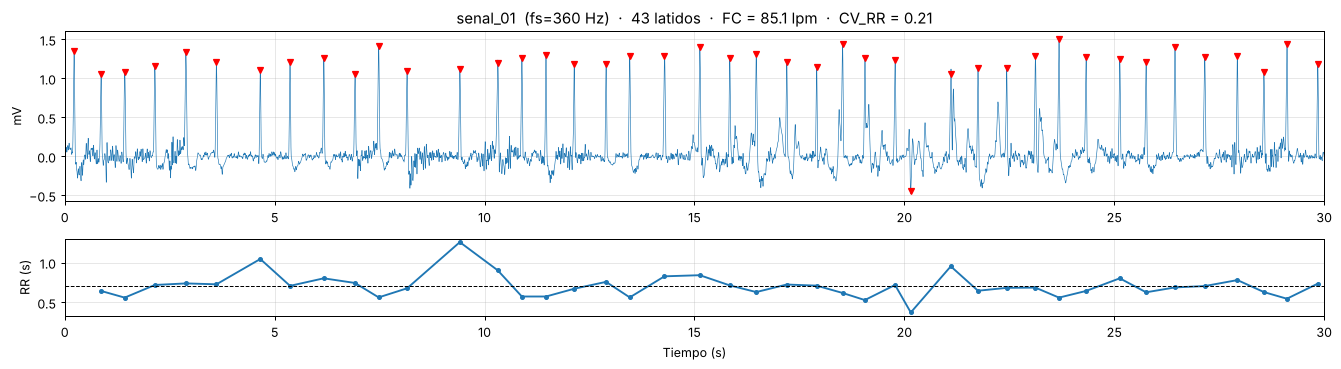

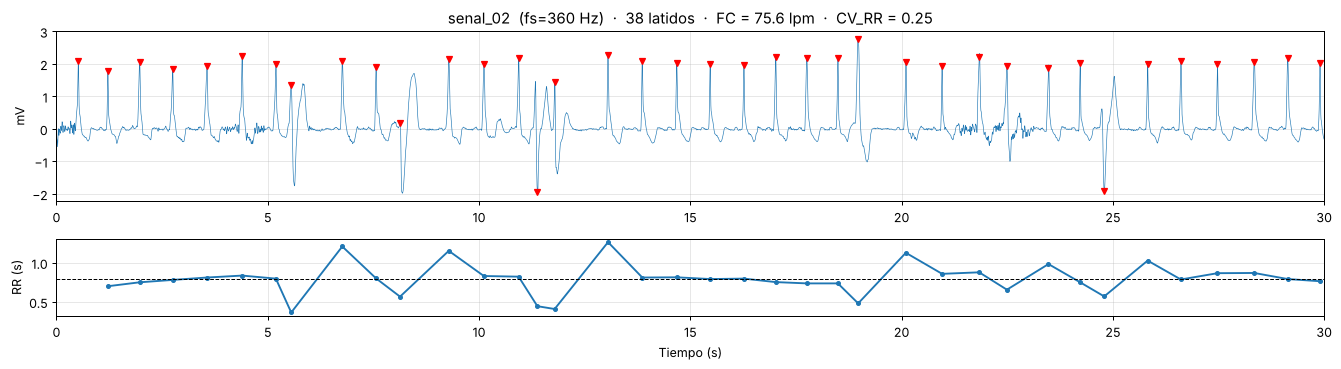

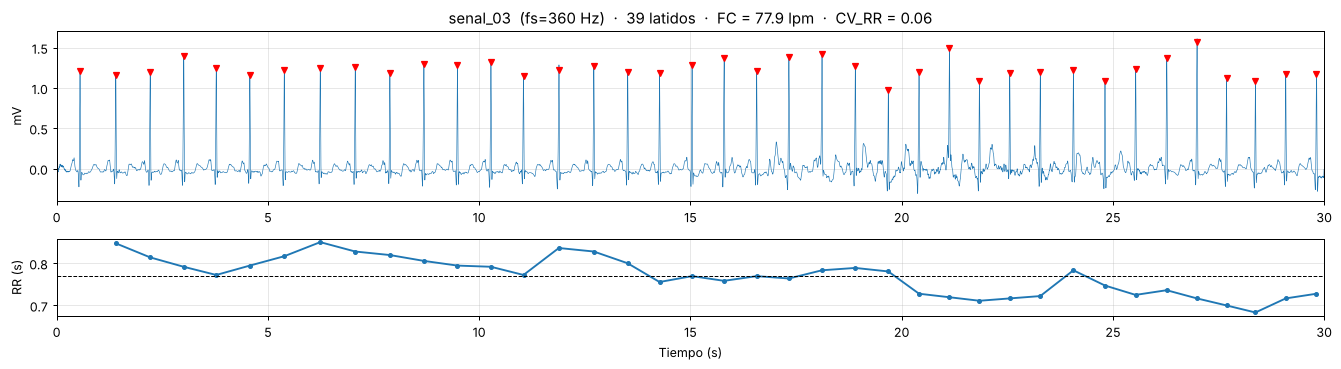

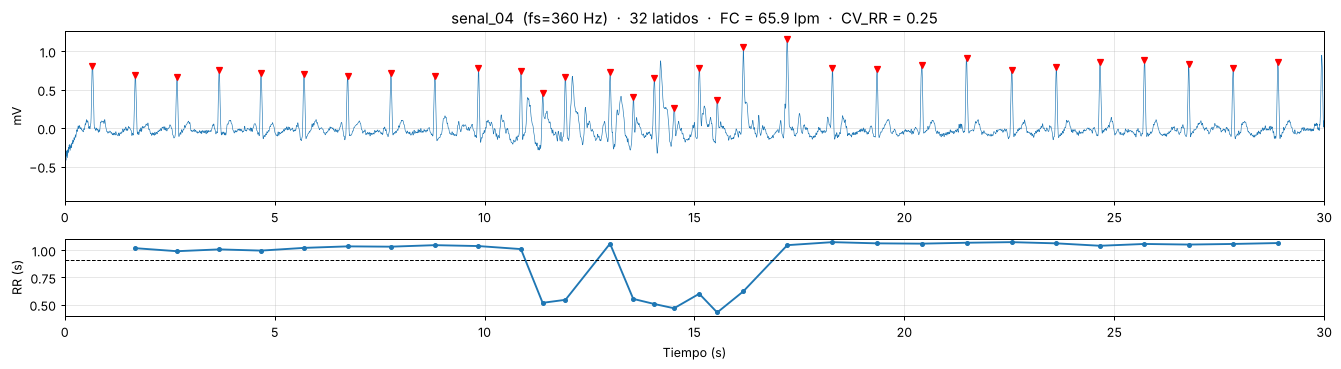

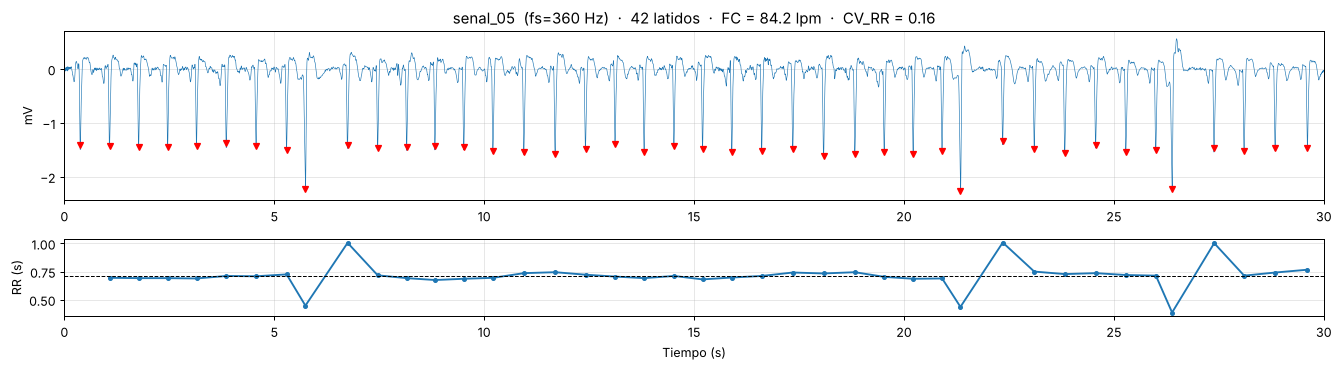

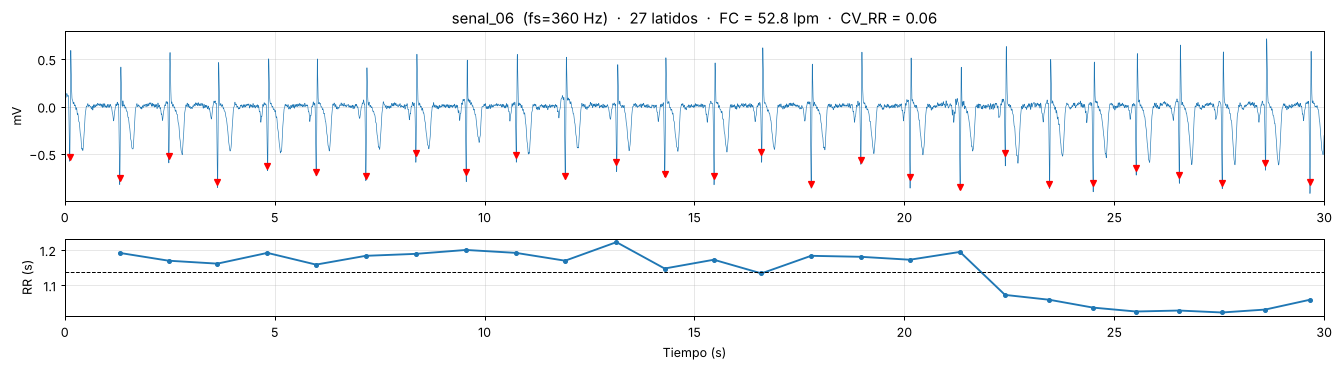

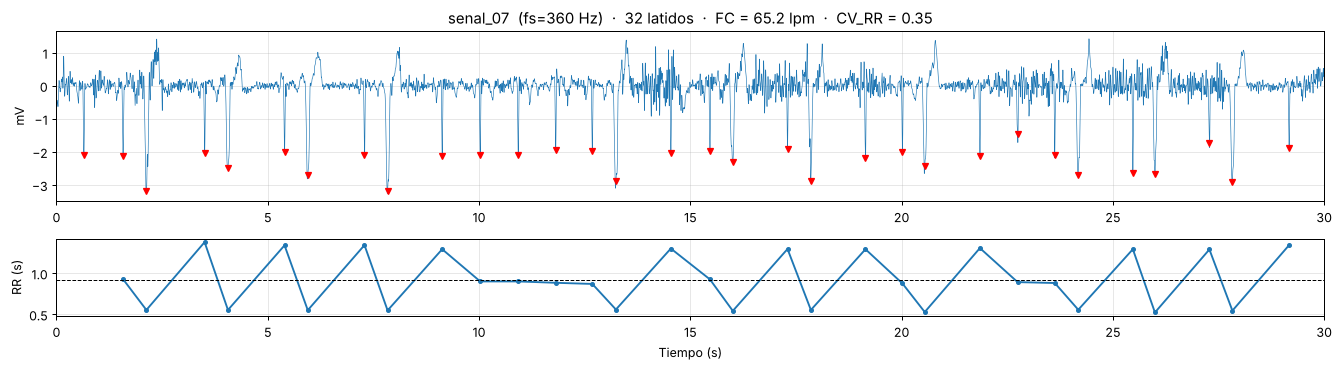

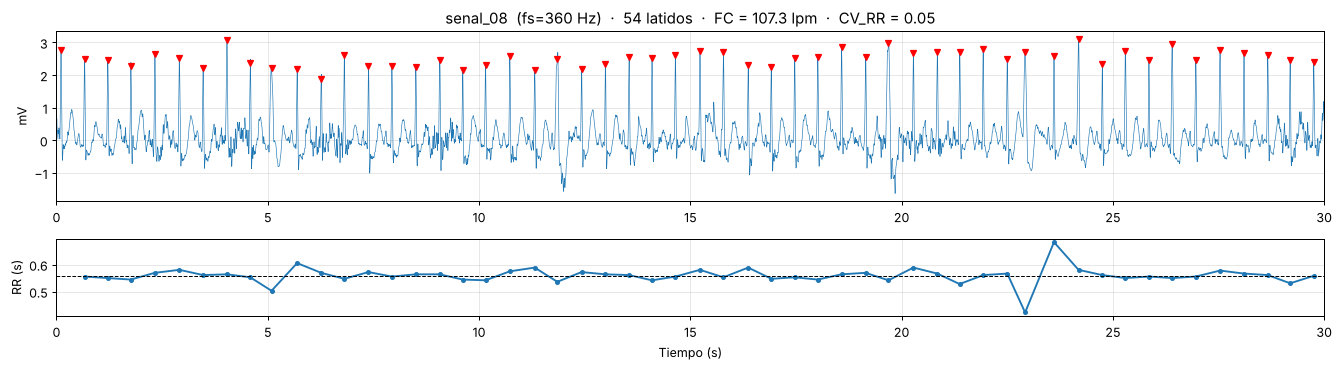

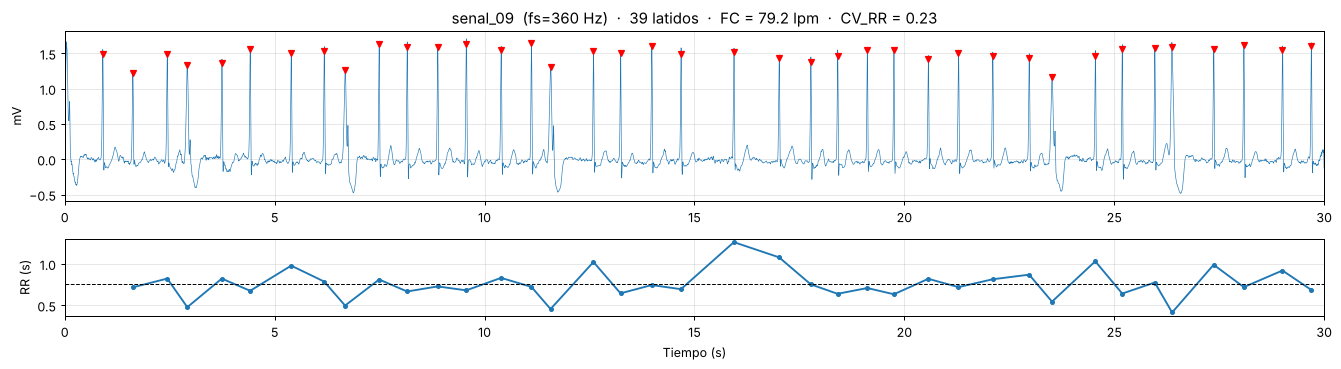

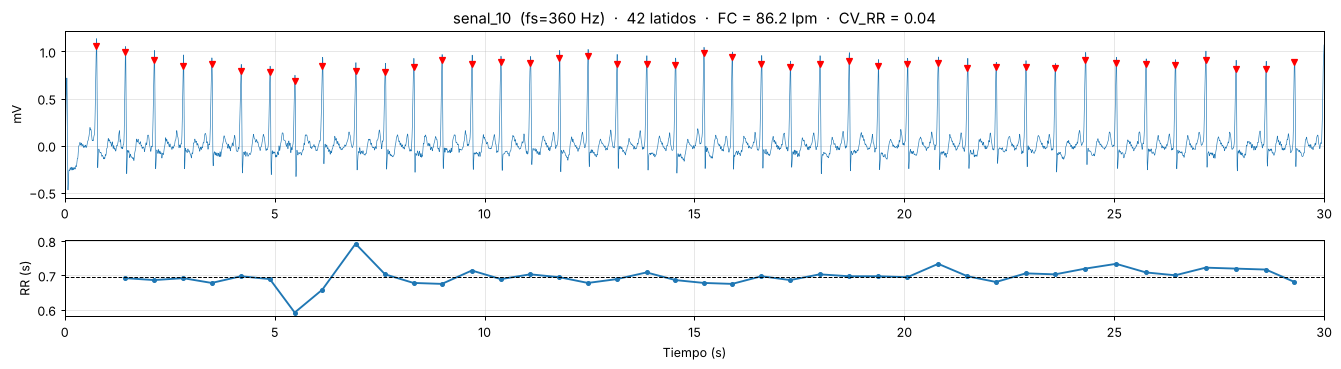

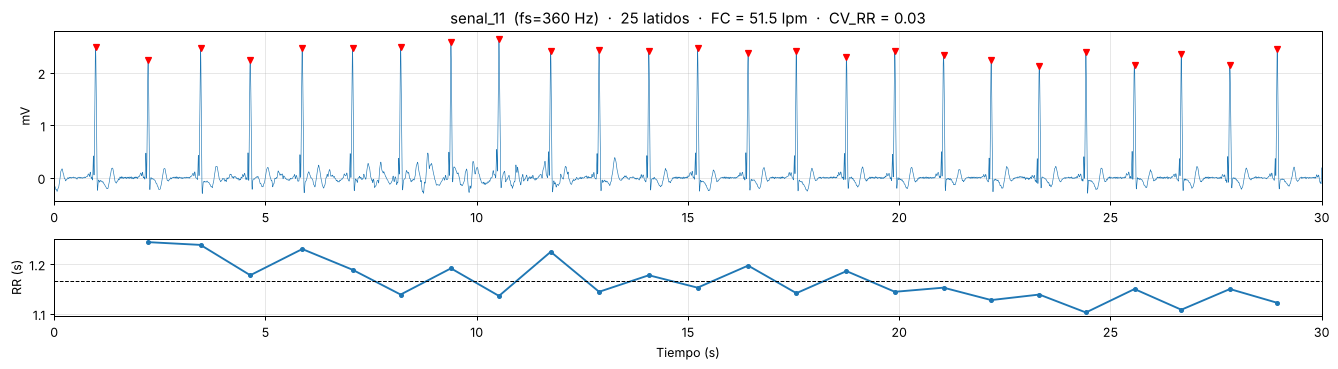

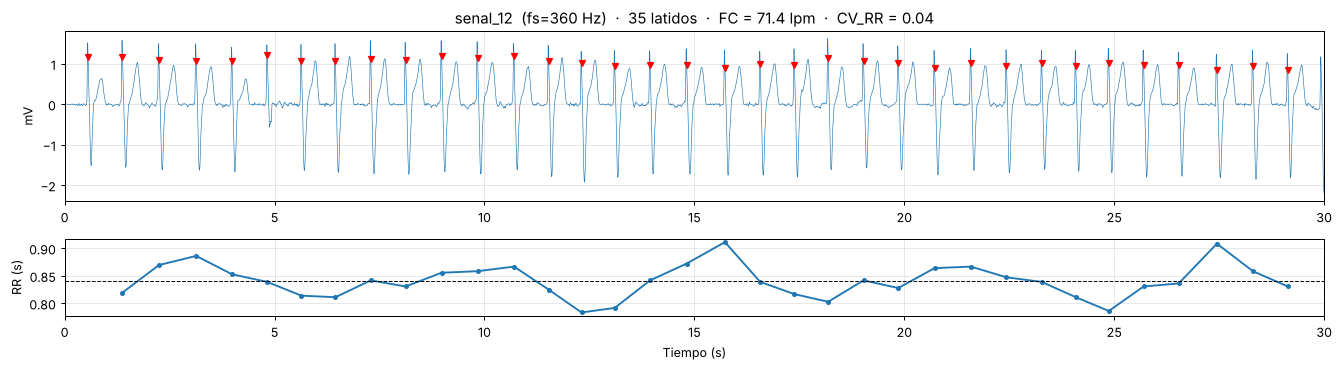

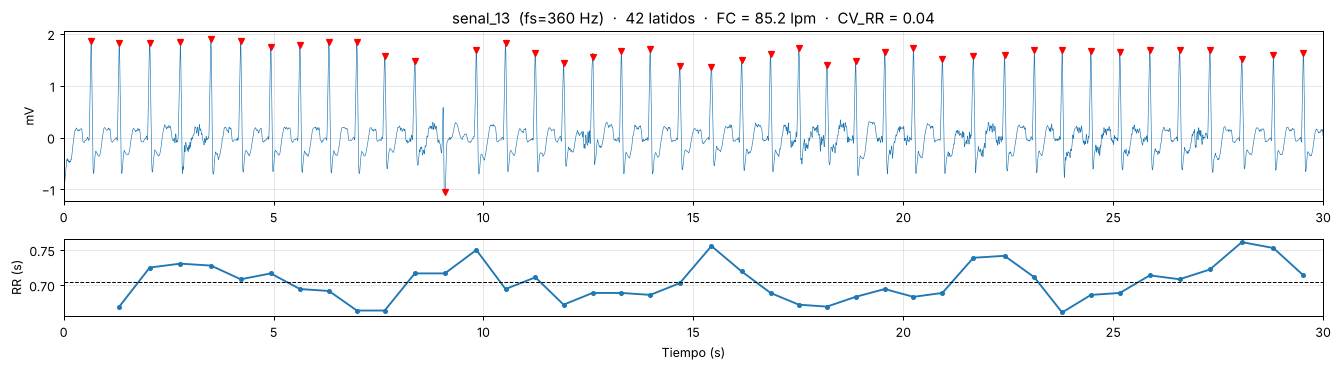

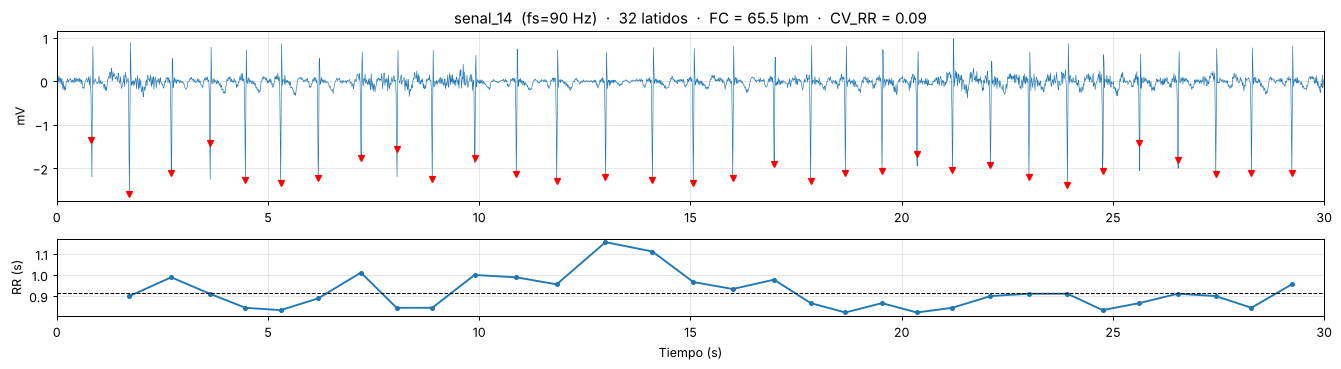

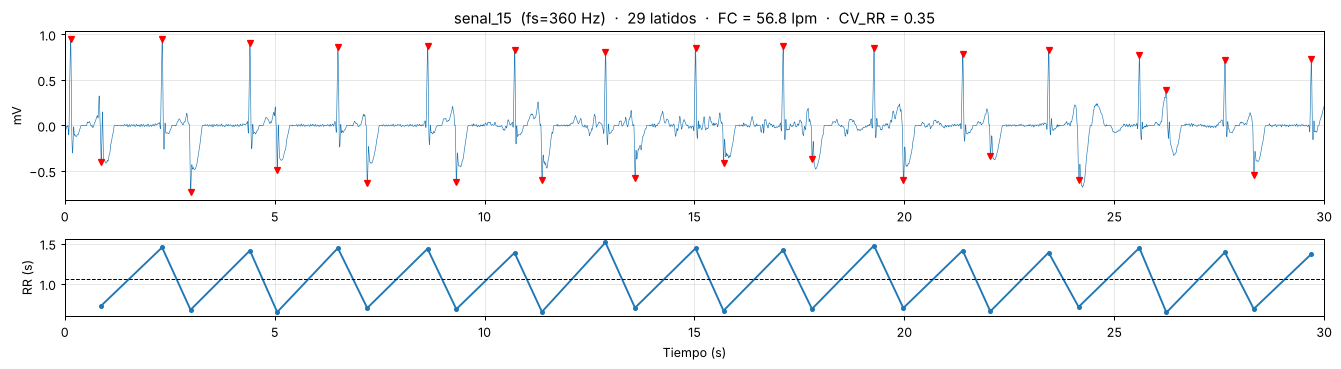

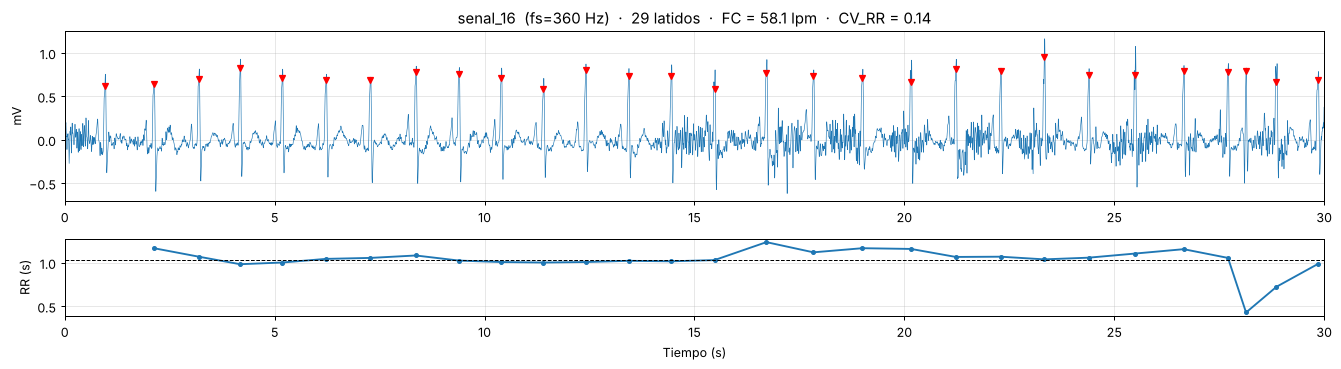

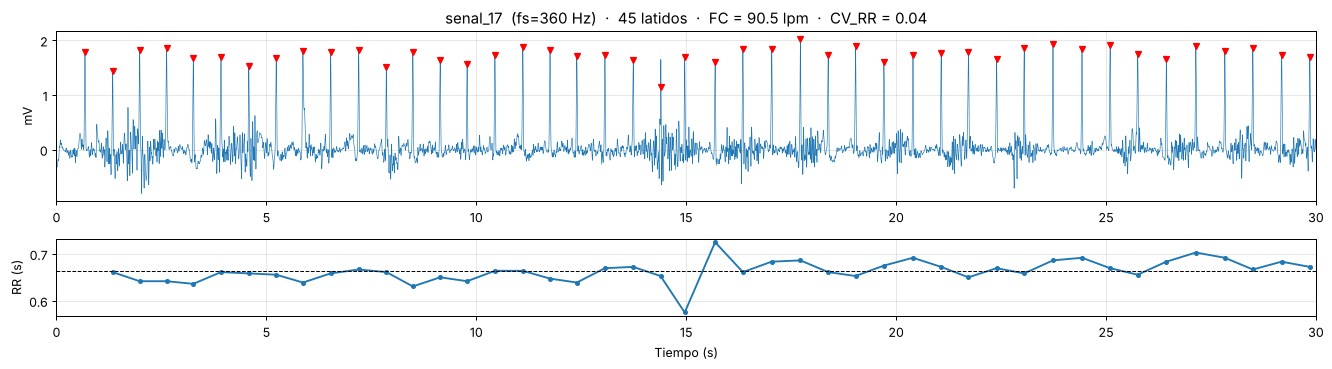

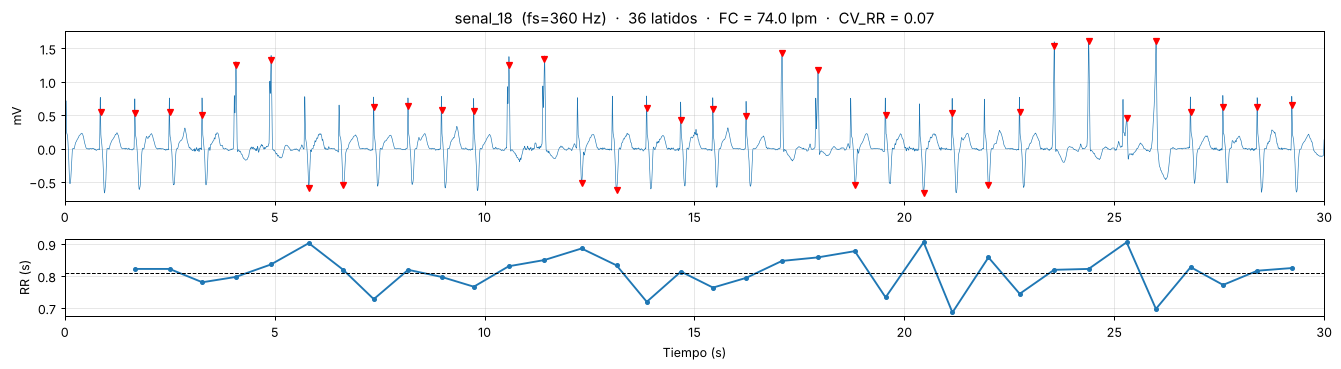

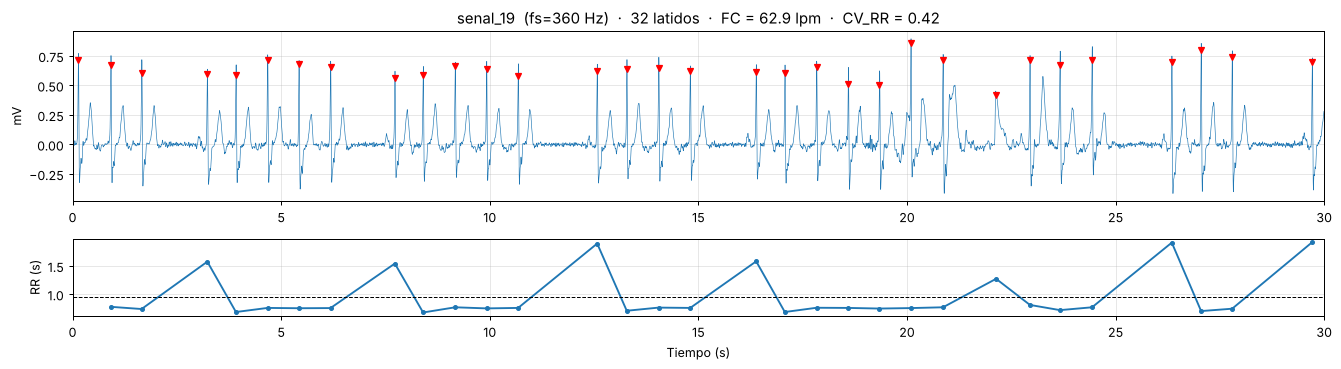

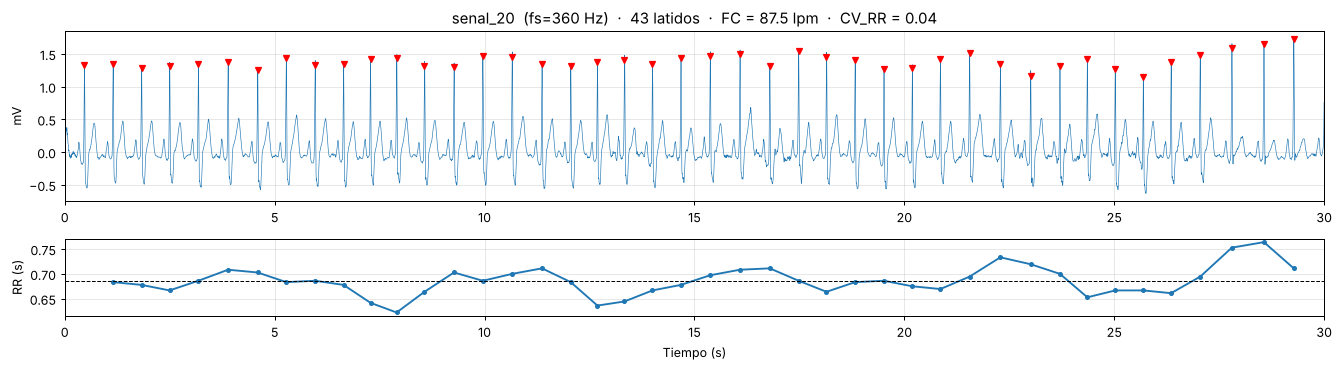

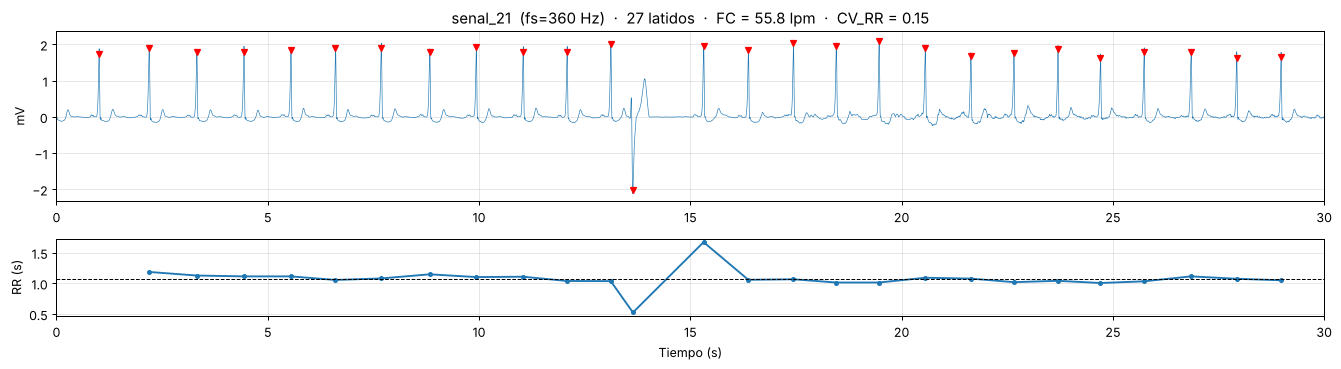

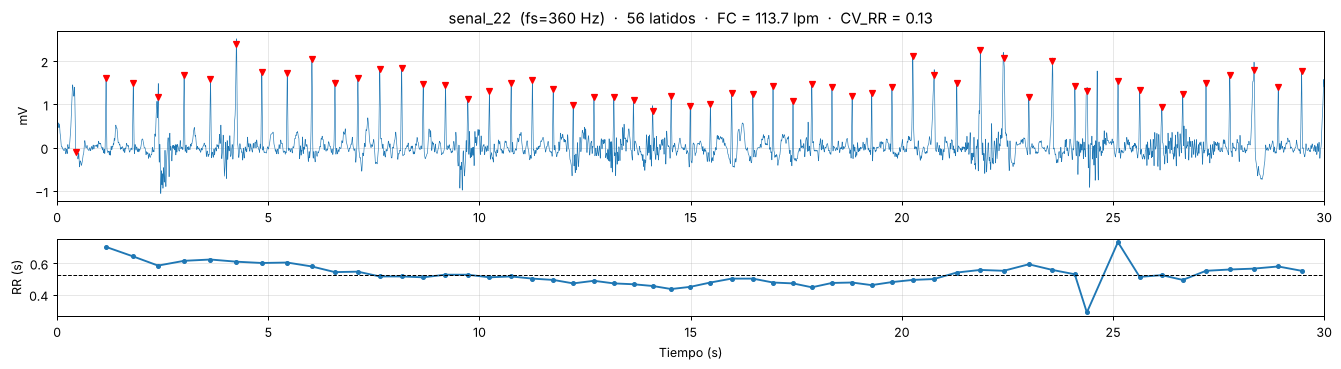

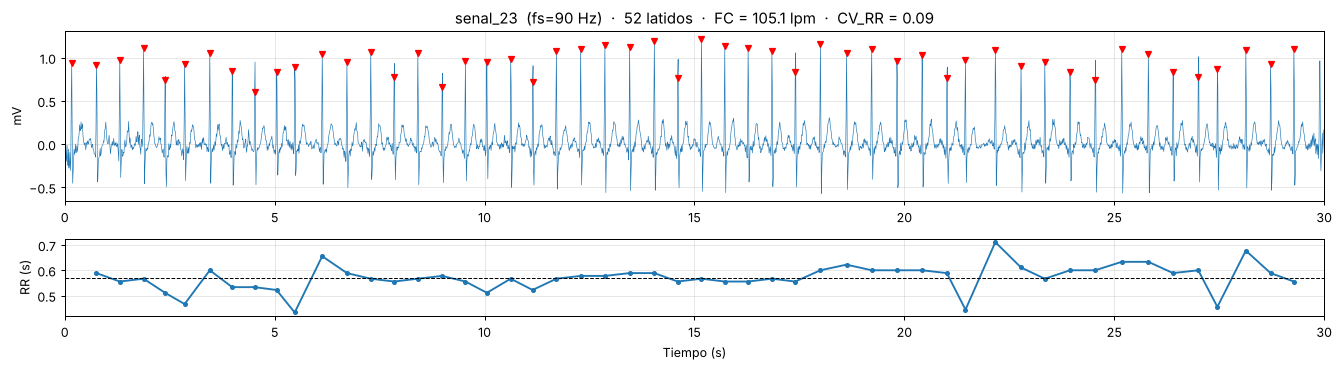

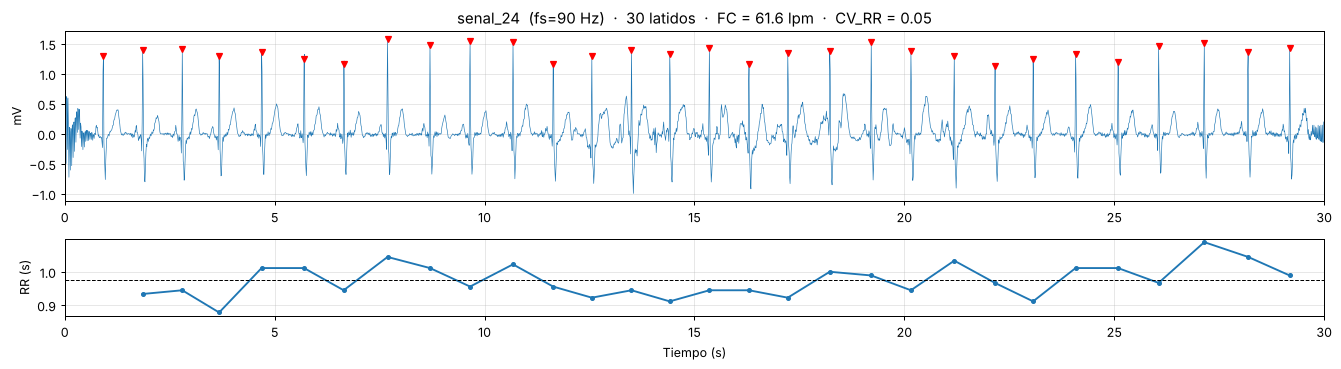

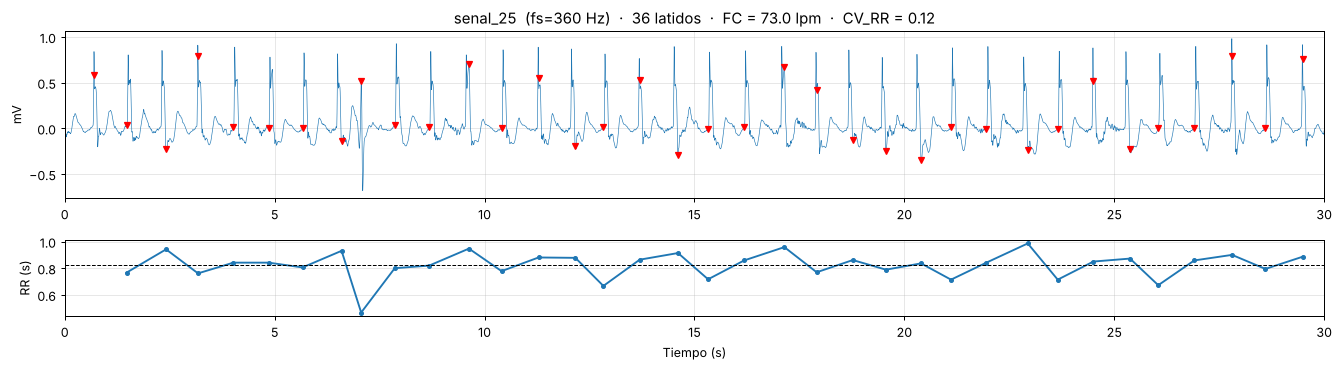

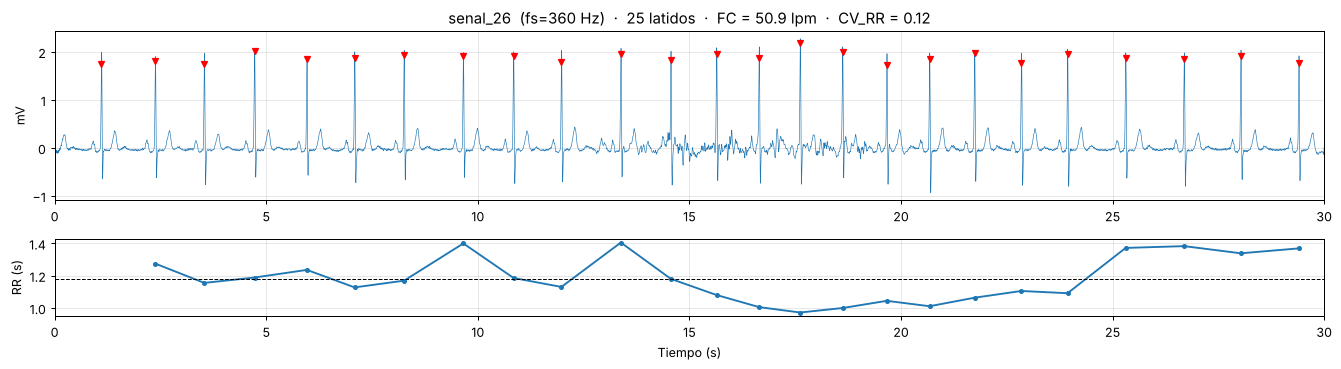

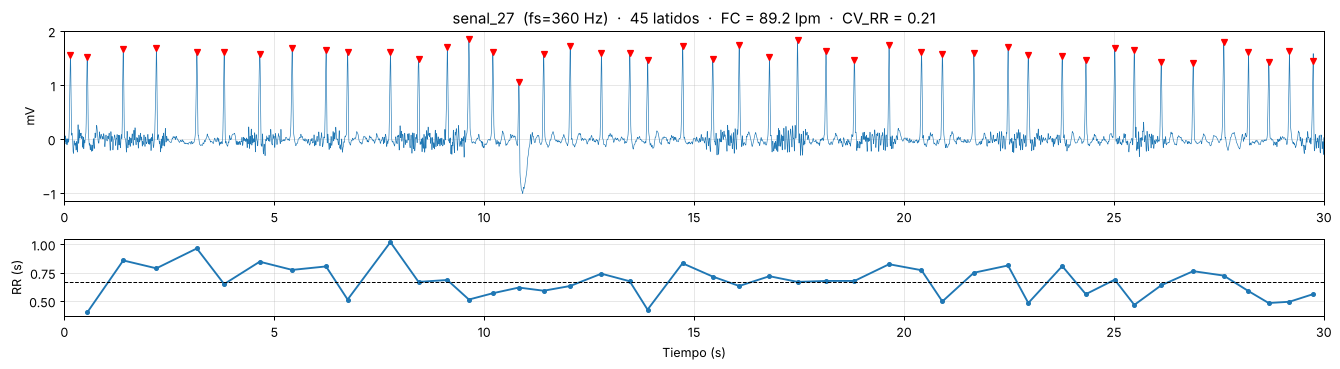

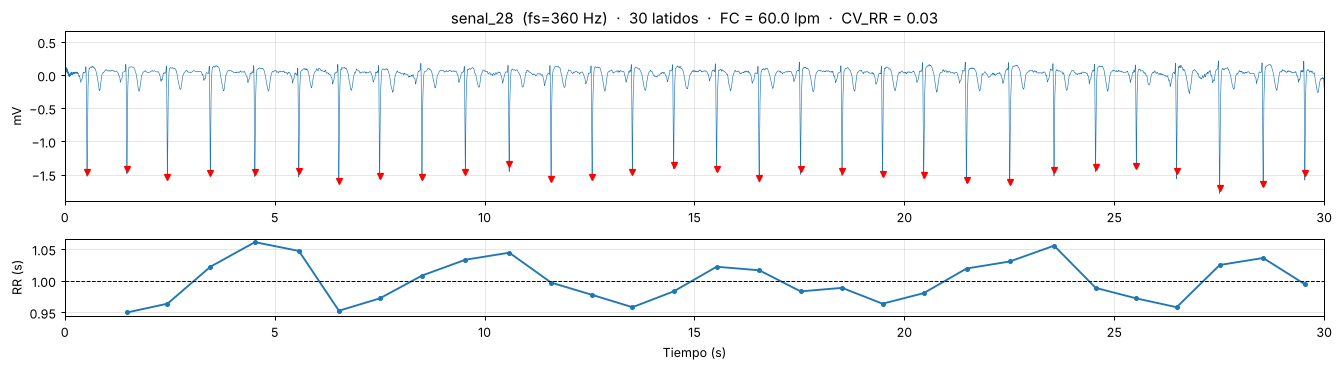

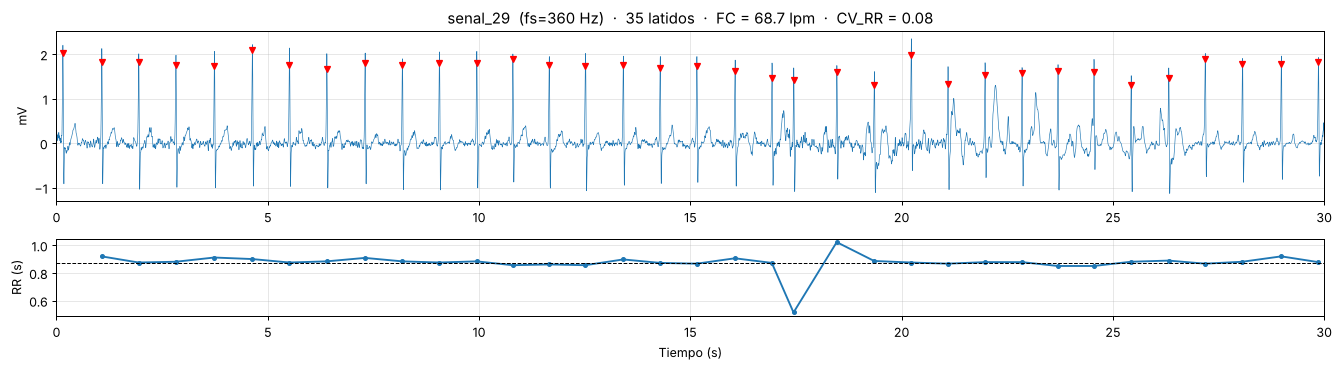

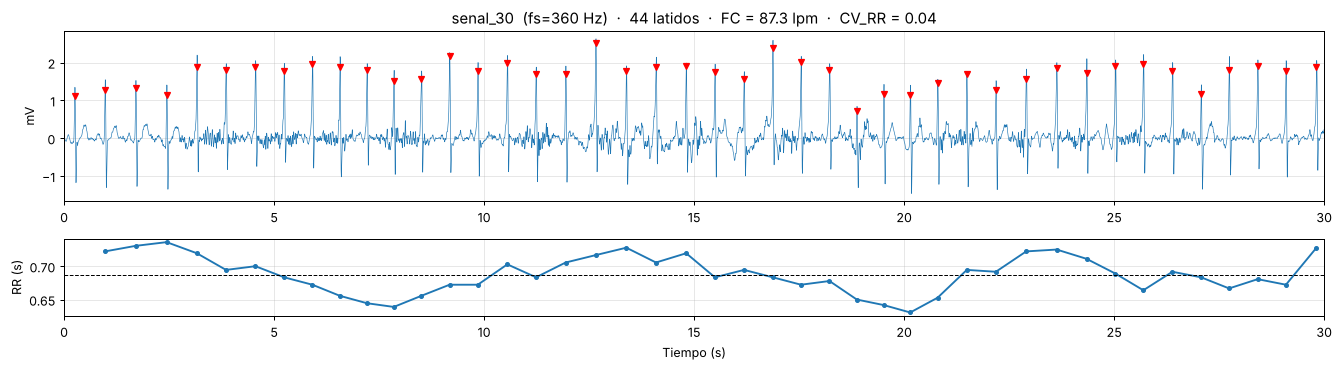

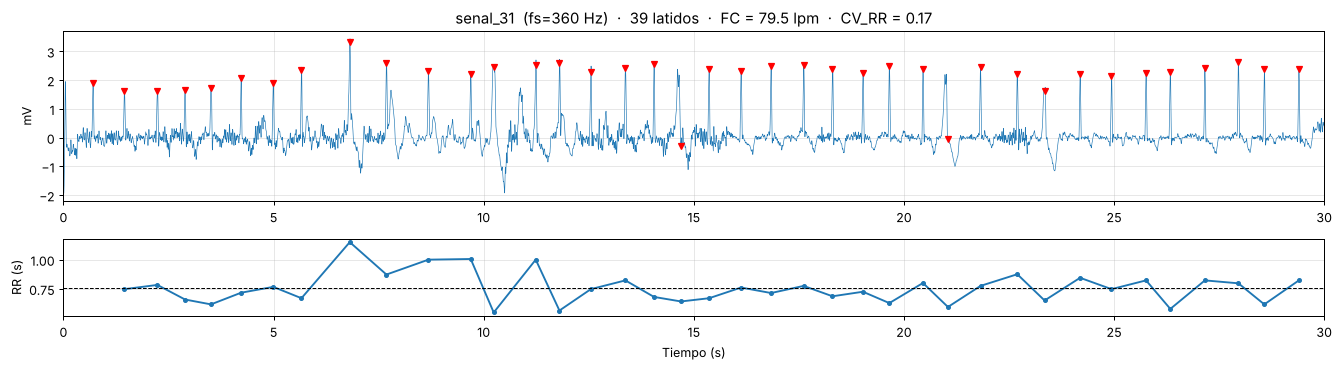

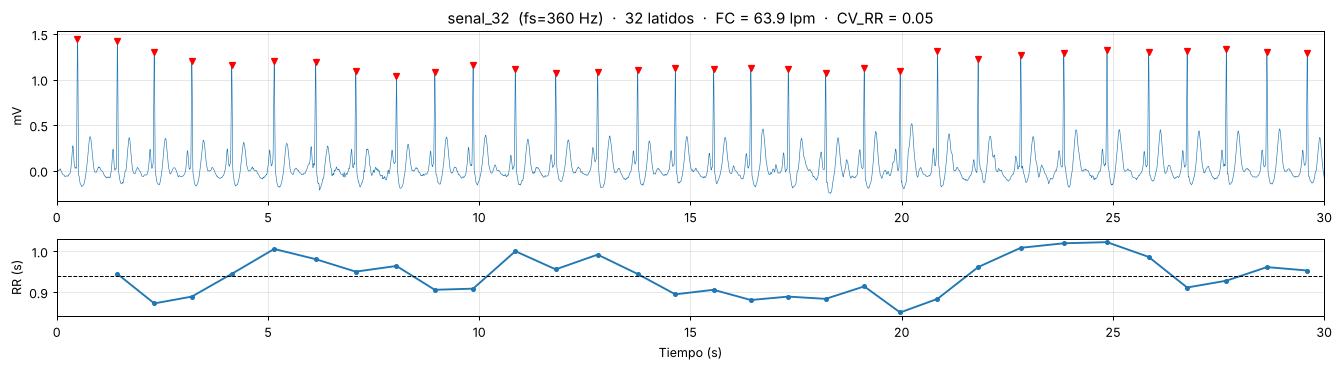

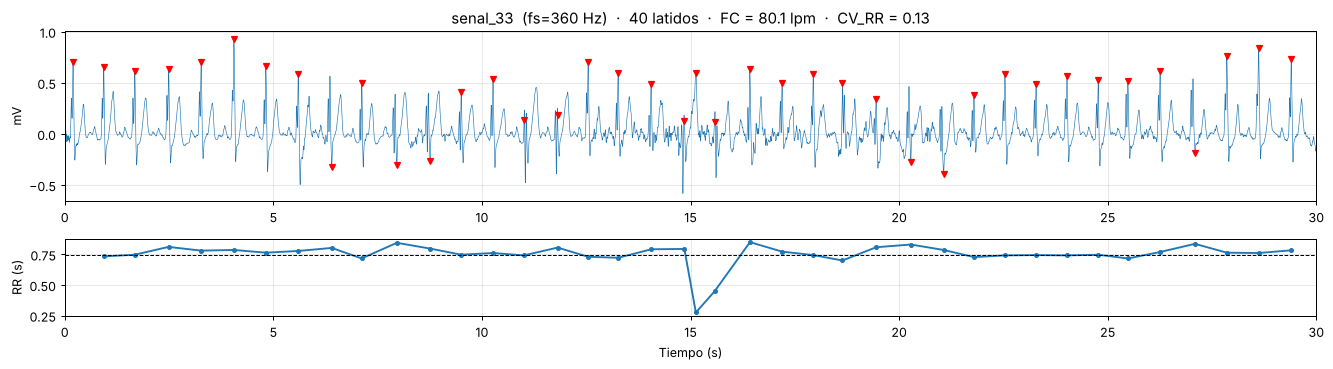

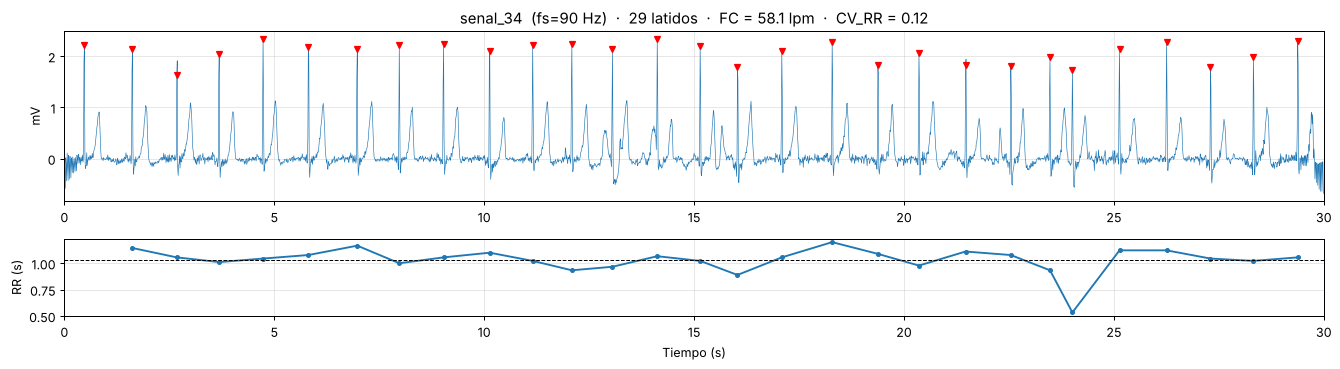

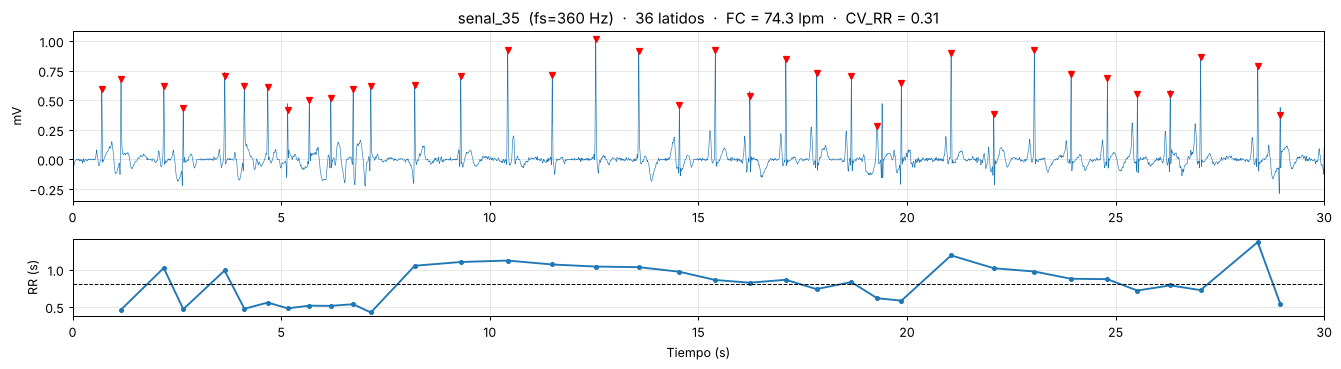

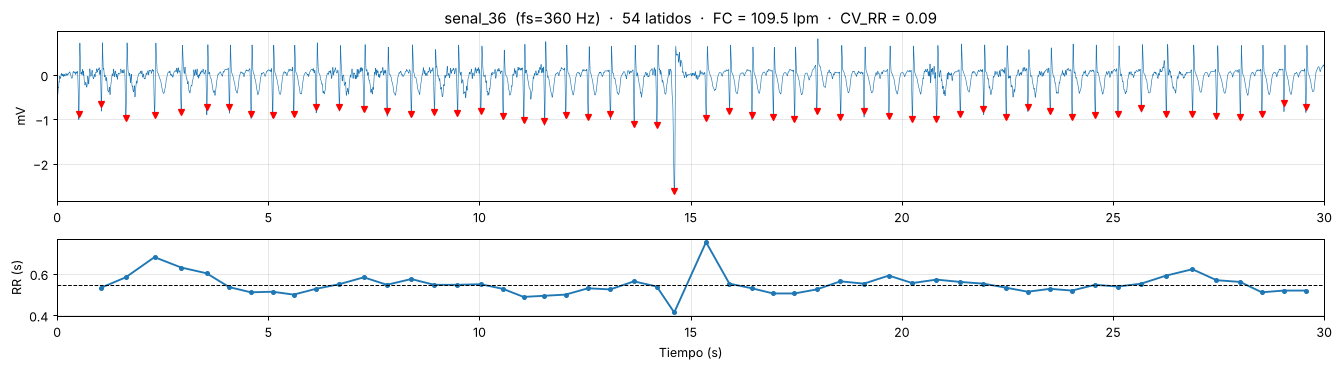

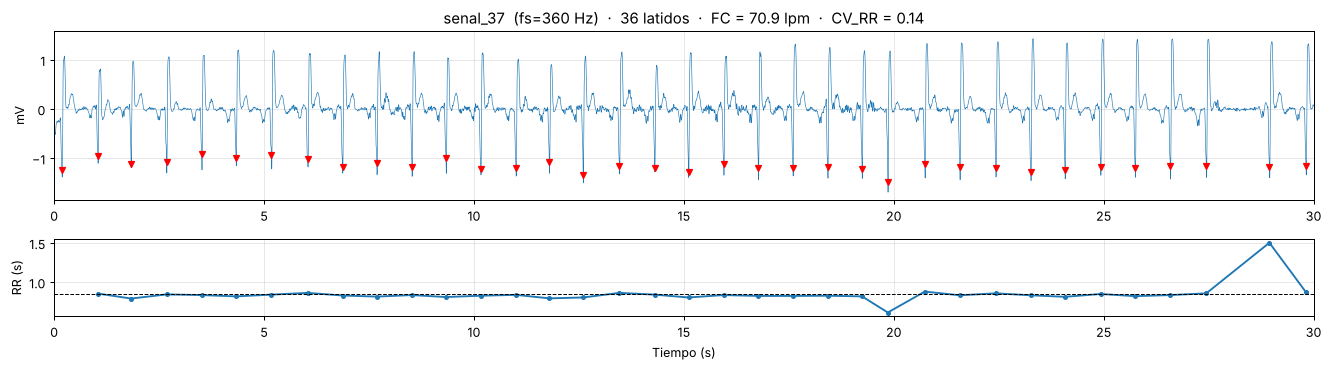

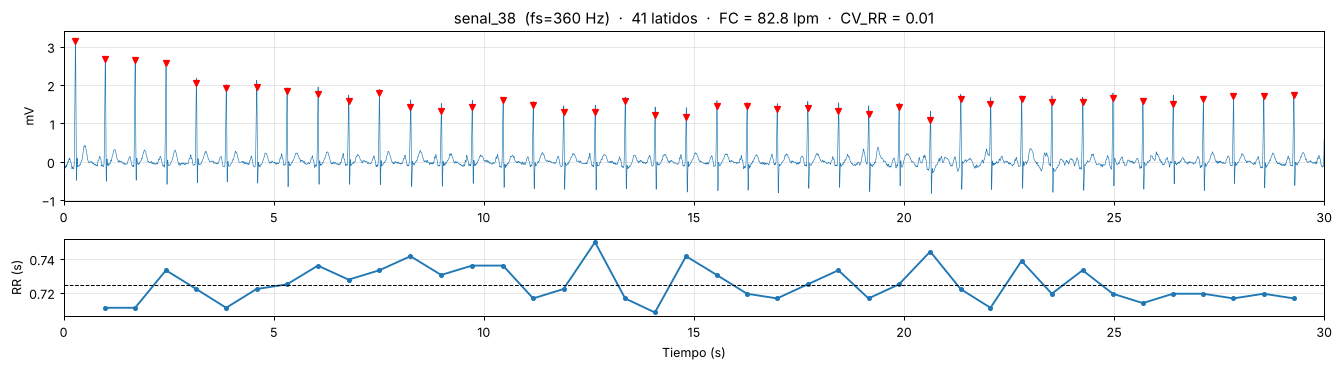

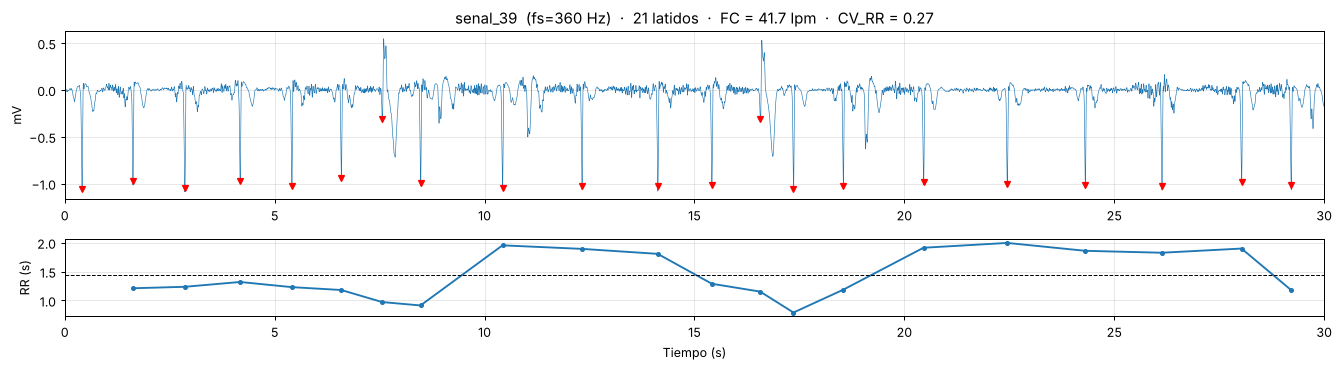

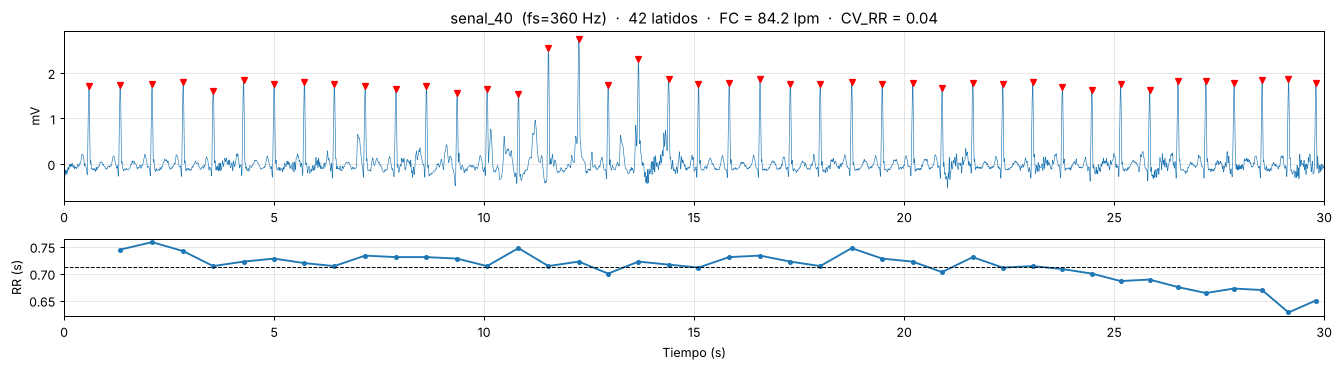

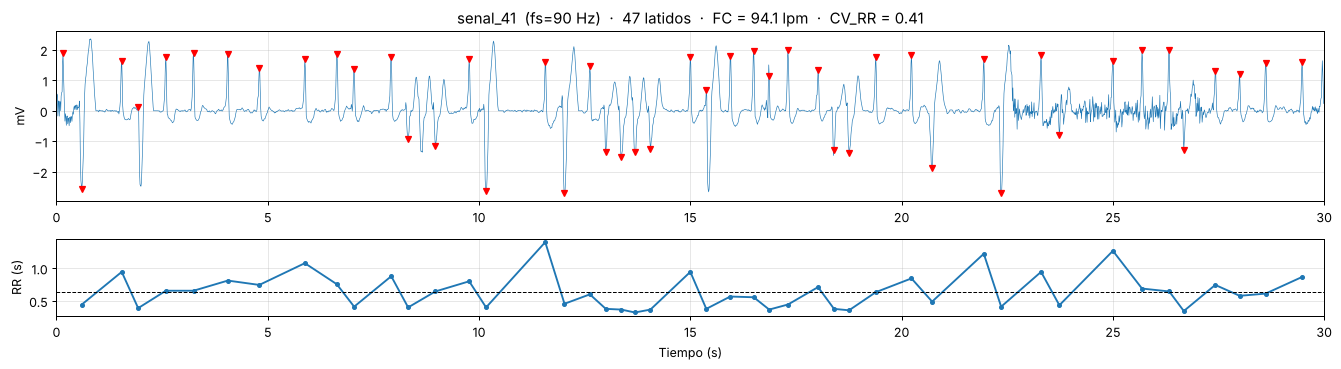

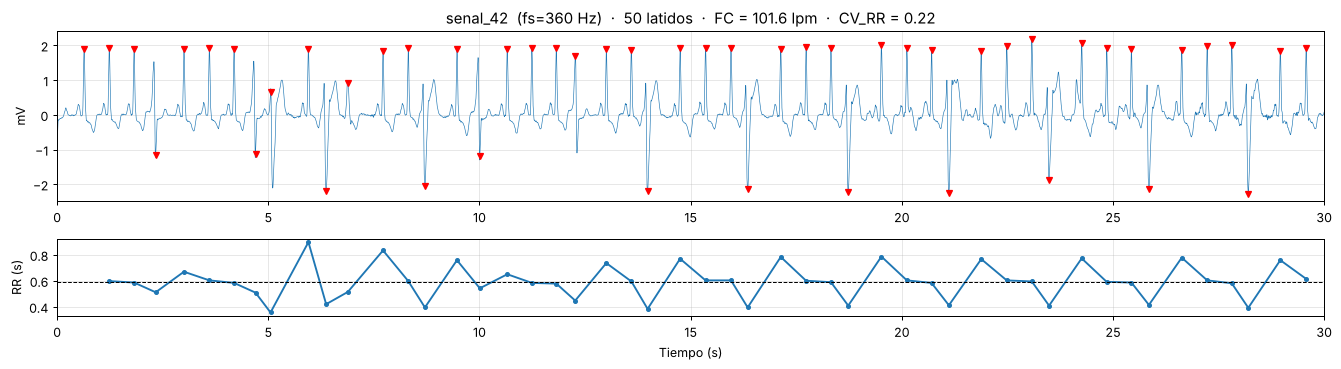

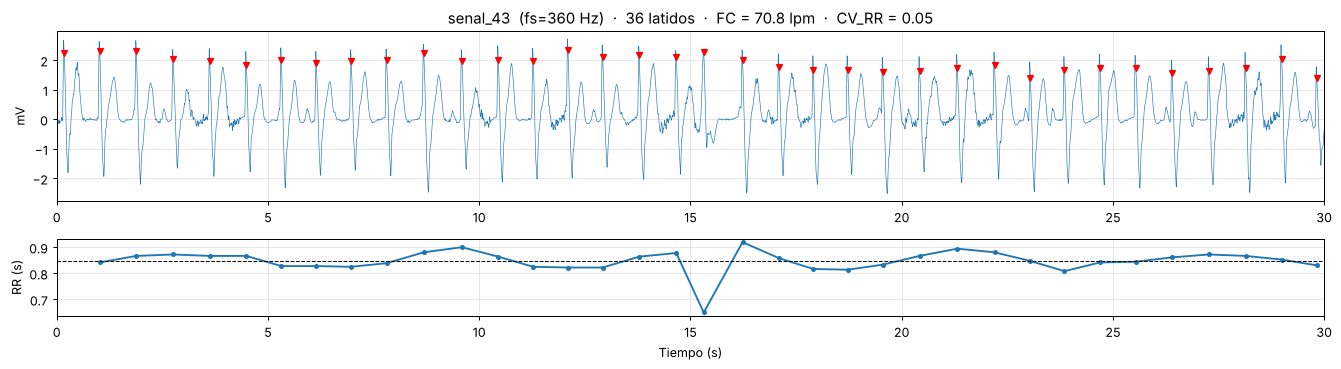

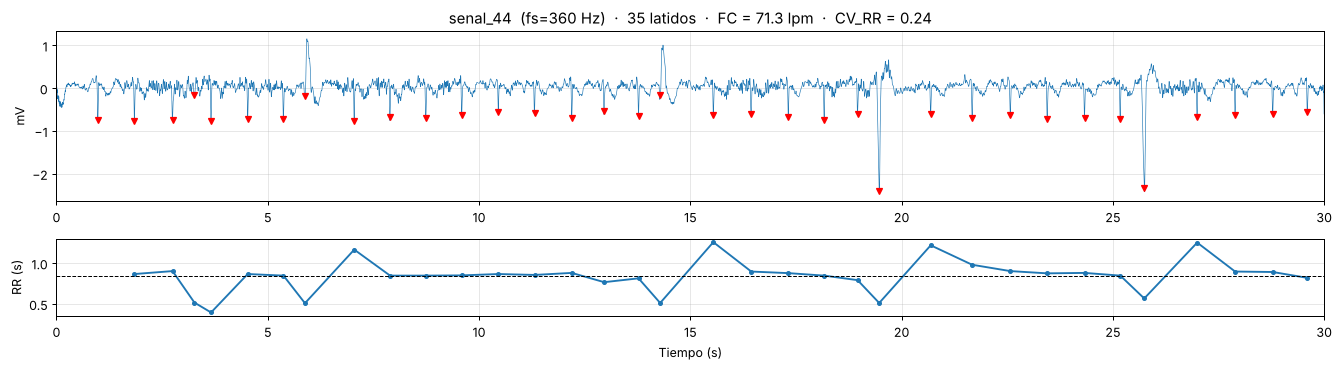

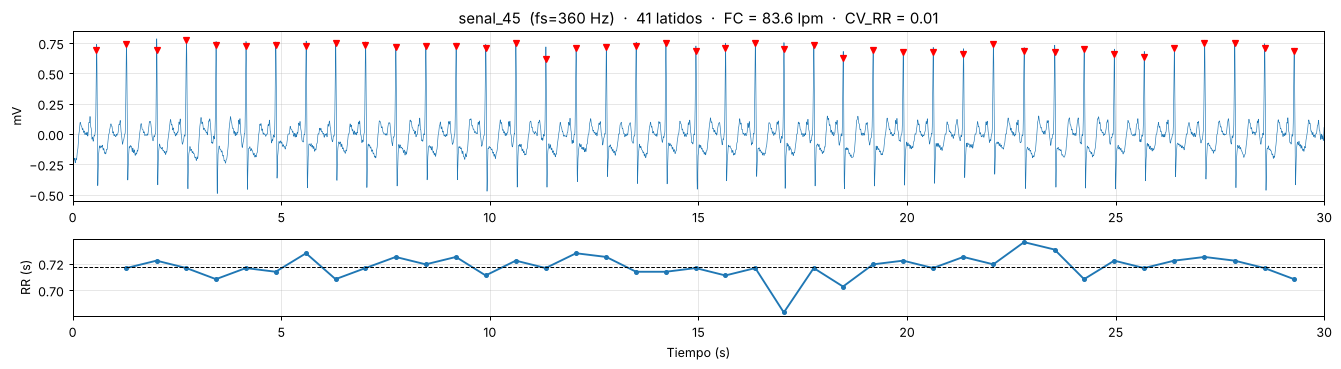

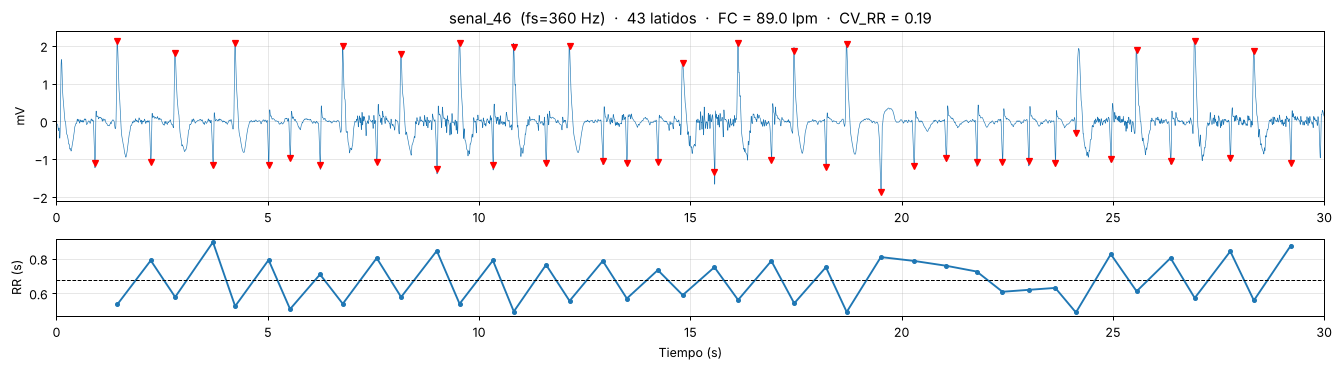

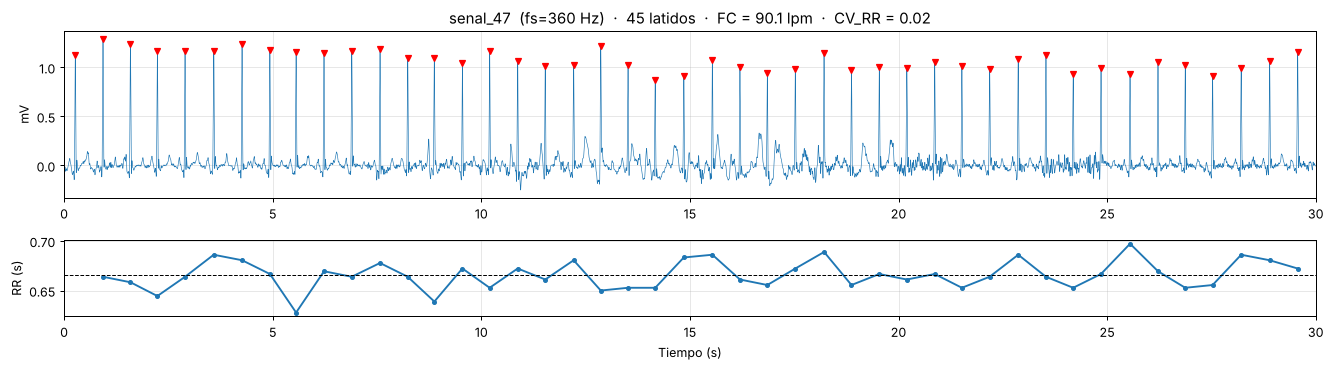

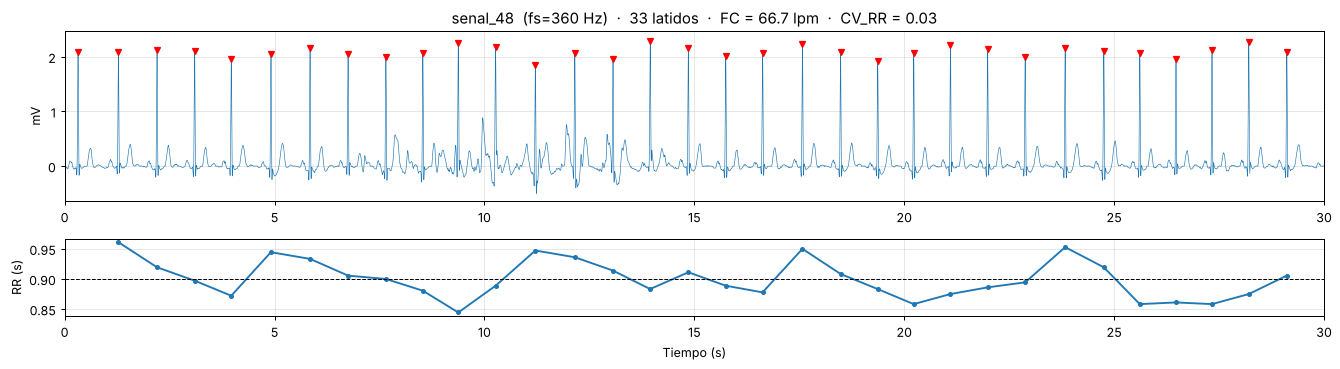

In [9]:
for i, res in resultados.items():
    d = senales[i]; fs = d["fs"]; t = d["t"]; r = res["r"]
    fig, ax = plt.subplots(2, 1, figsize=(15, 4.2), gridspec_kw={"height_ratios": [2.2, 1]})
    ax[0].plot(t, res["vista"], lw=0.5)
    ax[0].plot(t[r], res["vista"][r], "rv", ms=5)
    ax[0].set(title=f"senal_{i:02d}  (fs={fs:.0f} Hz)  ·  {len(r)} latidos  ·  FC = {res['fc']:.1f} lpm  ·  CV_RR = {np.std(res['rr'])/np.mean(res['rr']):.2f}",
              ylabel="mV", xlim=(0, 30))
    ax[1].plot(t[r[1:]], res["rr"], "o-", ms=3)
    ax[1].axhline(np.mean(res["rr"]), color="k", ls="--", lw=0.8)
    ax[1].set(ylabel="RR (s)", xlabel="Tiempo (s)", xlim=(0, 30))
    plt.tight_layout(); plt.show()

### **6.2 Comparación con un detector independiente (NeuroKit2)**
Como no tengo la FC de referencia, comparo mis resultados con los del detector por defecto de **NeuroKit2** (Makowski et al., 2021), una librería de código abierto de procesamiento de señales fisiológicas. Le paso la señal después del notch, para que la comparación sea justa. Si ambos métodos coinciden, gano confianza. Si no coinciden, reviso la señal a mano.

> Si NeuroKit2 no está instalado, la celda lo indica y sigue (se instala con `pip install neurokit2`). Esta comparación **no** modifica mis resultados: solo sirve para validar.

In [10]:
try:
    import neurokit2 as nk
    import warnings; warnings.filterwarnings("ignore")
    comp = []
    for i, res in resultados.items():
        fs = int(senales[i]["fs"])
        limpia = nk.ecg_clean(res["notch"], sampling_rate=fs)
        _, info = nk.ecg_peaks(limpia, sampling_rate=fs)
        fc_nk = 60.0 / np.mean(np.diff(info["ECG_R_Peaks"]) / fs)
        comp.append({"senal": i, "FC_mia": round(res["fc"], 1), "FC_NeuroKit2": round(fc_nk, 1),
                     "diferencia": round(res["fc"] - fc_nk, 1)})
    comp = pd.DataFrame(comp).set_index("senal")
    print("Coinciden (|dif| ≤ 2 lpm):", (comp.diferencia.abs() <= 2).sum(), "de 48")
    print("Discrepan:", list(comp.index[comp.diferencia.abs() > 2]))
    display(comp[comp.diferencia.abs() > 2])
except ImportError:
    print("NeuroKit2 no está instalado; omito esta comparación.")

Coinciden (|dif| ≤ 2 lpm): 37 de 48
Discrepan: [5, 7, 9, 11, 15, 16, 26, 33, 34, 39, 41]


,FC_mia,FC_NeuroKit2,diferencia
senal,,,
5,84.2,67.8,16.4
7,65.2,61.0,4.2
9,79.2,81.3,-2.1
11,51.5,57.9,-6.4
15,56.8,54.2,2.7
16,58.1,60.2,-2.1
26,50.9,55.1,-4.2
33,80.1,78.0,2.1
34,58.1,91.3,-33.2


**Cómo resolví las discrepancias:** revisé a mano cada señal en la que los dos métodos difieren más de 2 lpm (gráficas de la sección 6.1 y zoom de la sección 7).
- **NeuroKit2 se equivoca y mi detector acierta:** en la 34 y la 39 cuenta ondas T altas como latidos; en la 11, 16 y 26 agrega detecciones pequeñas que no son QRS; en la 5 y la 7 pierde latidos de QRS negativo y extrasístoles. En la 5, por ejemplo, el tacograma muestra el patrón clásico de extrasístole (RR corto seguido de pausa compensatoria) y todos los QRS están marcados.
- **Diferencias pequeñas (≈ 2 lpm) por un latido de más o de menos en un tramo con ruido:** 9 y 33.
- **Casos realmente dudosos, en los que ninguno de los dos métodos es concluyente:** 15 y sobre todo 41 (ver sección 7).

## **7. Análisis crítico de los casos más drásticos**
Hago zoom en las señales más difíciles. La interpretación clínica es solo una hipótesis a partir de la morfología; no soy médico y no la uso para cambiar la FC.

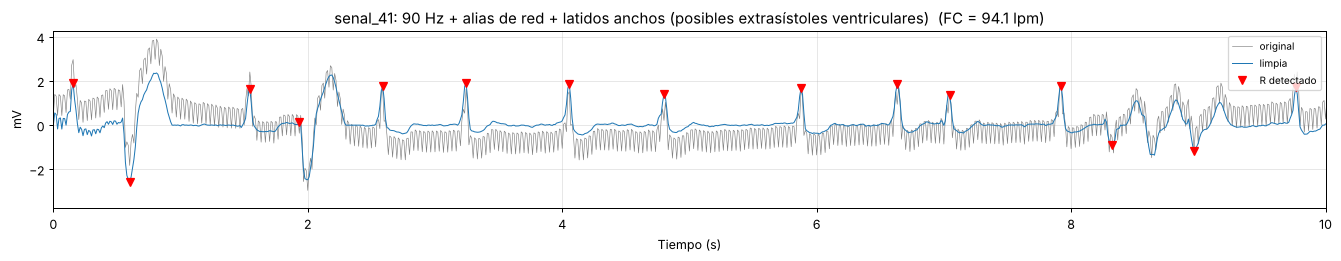

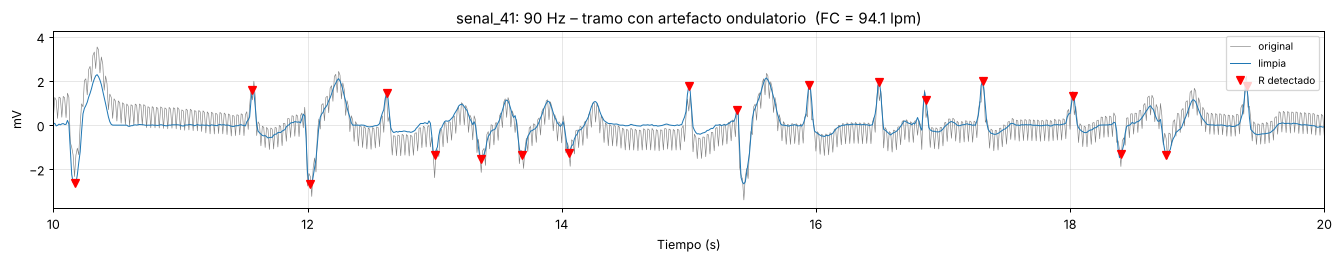

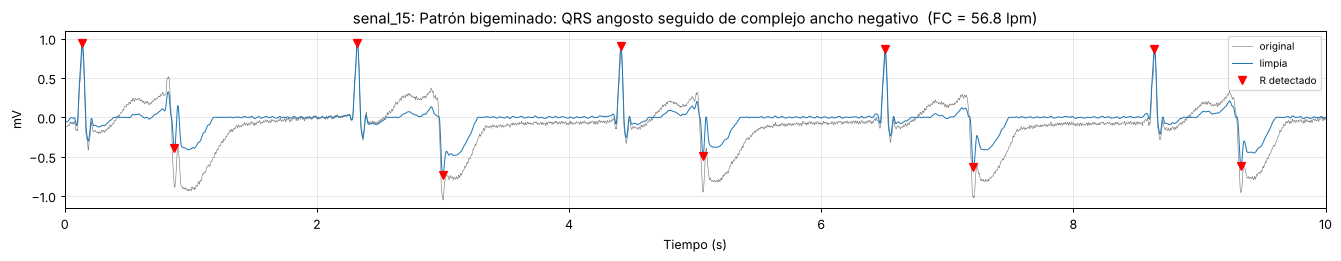

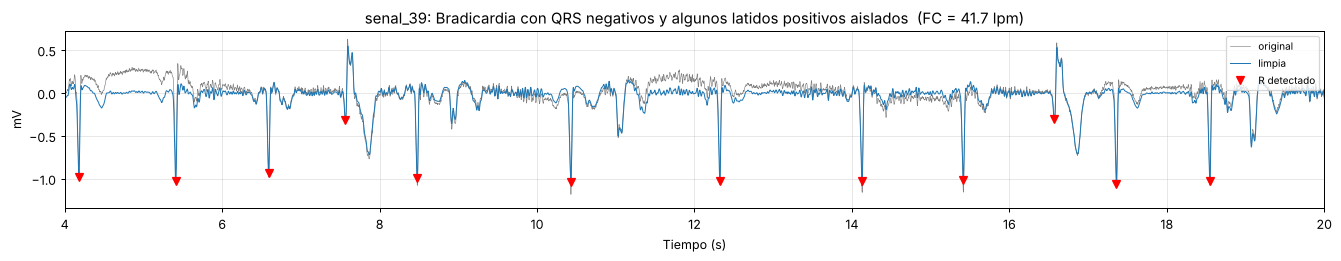

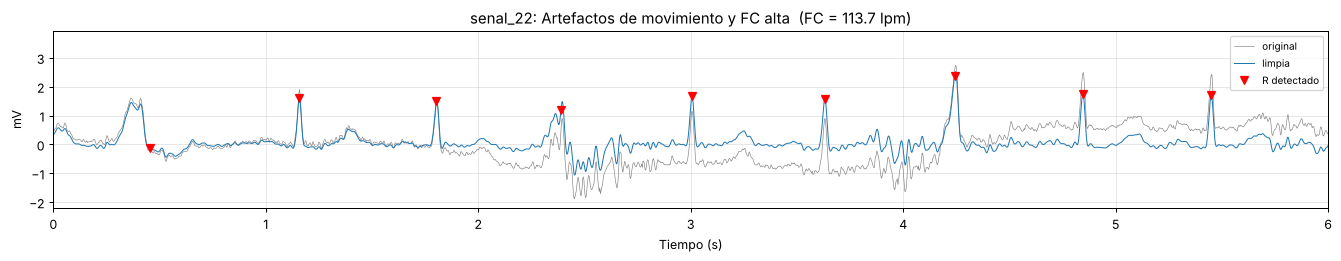

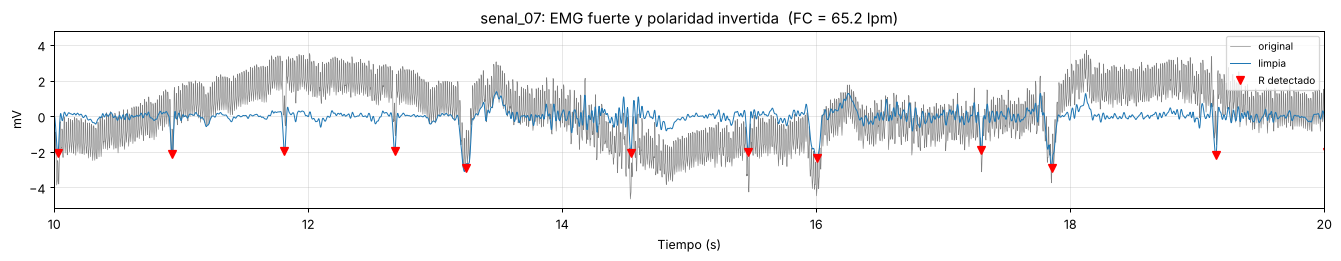

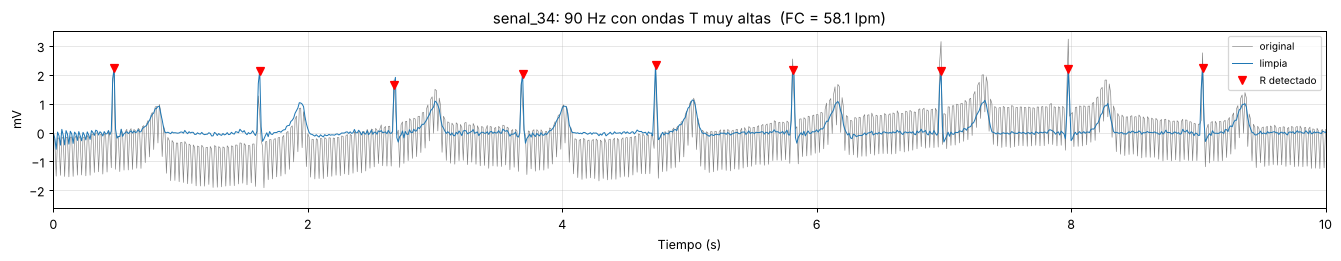

In [11]:
casos = [(41, 0, 10, "90 Hz + alias de red + latidos anchos (posibles extrasístoles ventriculares)"),
         (41, 10, 20, "90 Hz – tramo con artefacto ondulatorio"),
         (15, 0, 10, "Patrón bigeminado: QRS angosto seguido de complejo ancho negativo"),
         (39, 4, 20, "Bradicardia con QRS negativos y algunos latidos positivos aislados"),
         (22, 0, 6, "Artefactos de movimiento y FC alta"),
         (7, 10, 20, "EMG fuerte y polaridad invertida"),
         (34, 0, 10, "90 Hz con ondas T muy altas")]
for i, t0, t1, desc in casos:
    d = senales[i]; res = resultados[i]; t = d["t"]; r = res["r"]
    fig, ax = plt.subplots(1, 1, figsize=(15, 3))
    ax.plot(t, d["x"] - np.median(d["x"]), color="gray", lw=0.5, label="original")
    ax.plot(t, res["vista"], lw=0.8, label="limpia")
    ax.plot(t[r], res["vista"][r], "rv", label="R detectado")
    ax.set(xlim=(t0, t1), title=f"senal_{i:02d}: {desc}  (FC = {res['fc']:.1f} lpm)", xlabel="Tiempo (s)", ylabel="mV")
    ax.legend(fontsize=8, loc="upper right"); plt.tight_layout(); plt.show()

### **Discusión**
- **Señal 41 (90 Hz):** es el caso más difícil. Combina el alias de la red en 30 Hz, que el notch elimina, latidos anchos de gran amplitud que parecen extrasístoles ventriculares y tramos con complejos anchos muy seguidos (alrededor de 8–9 s, 13–14 s y 18–19 s, con RR ≈ 0.35 s). Esos tramos pueden ser rachas de extrasístoles, y entonces son latidos reales, o un artefacto, y entonces sobran. Yo los cuento (FC ≈ 94 lpm). Si fueran artefacto, la FC estaría más cerca de 75 lpm, que es lo que da NeuroKit2. Es la señal con mayor incertidumbre del conjunto. **Mejora posible:** clasificar los latidos por correlación con una plantilla del QRS para descartar los candidatos que no se parecen ni al latido normal ni al ectópico.
- **Señal 15:** cada QRS angosto va seguido, ~0.7 s después, de un complejo ancho negativo, y luego hay una pausa de ~1.45 s. Es compatible con un **bigeminismo ventricular** (latido normal + extrasístole + pausa compensatoria). Cuento ambos complejos como latidos porque los dos son despolarizaciones ventriculares. Si los complejos anchos no fueran latidos, la FC sería la mitad (~28 lpm), lo que es fisiológicamente poco probable con ese patrón.
- **Señal 39:** tiene la FC más baja (~42 lpm), con RR de hasta 2 s. Las deflexiones pequeñas entre QRS tienen la forma y la posición de ondas T, no de QRS, así que no las cuento. NeuroKit2 sí las cuenta y obtiene una FC mayor.
- **Señal 22:** hay artefactos de movimiento grandes (por ejemplo, cerca de 2.6 s). La regla de 0.3 s (más de 200 lpm imposible) elimina la detección espuria.
- **Señal 7:** el EMG es fuerte y el QRS es negativo. El cuadrado del detector de Pan y Tompkins lo hace insensible a la polaridad y el pasa-banda reduce el EMG, así que detecto todos los latidos.
- **Señal 34 (90 Hz):** las ondas T son casi tan altas como las R. La derivada y el pasa-banda 5–15 Hz favorecen las pendientes rápidas del QRS, y la regla de la onda T evita contarlas. NeuroKit2 las cuenta como latidos y casi duplica la FC.

### **Limitaciones generales y posibles mejoras**
1. **Las señales de 90 Hz** perdieron el contenido por encima de 45 Hz, y el ruido de banda ancha que había por encima pudo plegarse dentro de la banda. Esto ya no se puede deshacer después del muestreo; la solución correcta es adquirir con filtro antialiasing y $f_s \ge 250$–$500$ Hz (Kligfield et al., 2007).
2. **El notch fijo** supone que la red está siempre en 60 Hz. Si su frecuencia variara, convendría un notch adaptativo (Hamilton, 1996).
3. **Los artefactos de movimiento** se solapan en frecuencia con el QRS. Ningún filtro lineal los separa por completo; haría falta clasificar la morfología de cada latido o usar varias derivaciones.

## **8. Resumen final**

In [12]:
final = pd.read_csv(ARCHIVO_RESULTADOS)
print(final.to_string(index=False))
print("\nFC media del grupo: %.1f lpm   (mín %.1f, máx %.1f)" % (final.FC_lpm.mean(), final.FC_lpm.min(), final.FC_lpm.max()))

   senal  FC_lpm
senal_01   85.06
senal_02   75.55
senal_03   77.91
senal_04   65.87
senal_05   84.17
senal_06   52.81
senal_07   65.21
senal_08  107.27
senal_09   79.20
senal_10   86.20
senal_11   51.48
senal_12   71.39
senal_13   85.19
senal_14   65.47
senal_15   56.85
senal_16   58.15
senal_17   90.49
senal_18   73.99
senal_19   62.89
senal_20   87.48
senal_21   55.78
senal_22  113.75
senal_23  105.11
senal_24   61.58
senal_25   72.97
senal_26   50.89
senal_27   89.20
senal_28   59.98
senal_29   68.65
senal_30   87.27
senal_31   79.47
senal_32   63.91
senal_33   80.13
senal_34   58.13
senal_35   74.34
senal_36  109.46
senal_37   70.87
senal_38   82.77
senal_39   41.67
senal_40   84.22
senal_41   94.13
senal_42  101.60
senal_43   70.83
senal_44   71.27
senal_45   83.61
senal_46   89.03
senal_47   90.11
senal_48   66.69

FC media del grupo: 76.3 lpm   (mín 41.7, máx 113.8)


## **9. Referencias**
1. **Oppenheim, A. V. y Schafer, R. W.** (2010). *Discrete-Time Signal Processing* (3.ª ed.). Pearson. ISBN 978-0-13-198842-2. Cap. 4 (Sec. 4.1–4.2 muestreo y aliasing), Cap. 5 (respuesta en frecuencia, polos y ceros, fase), Cap. 7 (diseño de filtros IIR, Butterworth), Cap. 8–10 (DFT, FFT, análisis espectral).
2. **Proakis, J. G. y Manolakis, D. G.** (2007). *Digital Signal Processing: Principles, Algorithms, and Applications* (4.ª ed.). Pearson Prentice Hall. ISBN 0-13-187374-1. Sec. 1.4.1 (frecuencia alias), Sec. 5.4 (filtros selectivos: resonadores y filtros notch).
3. **Pan, J. y Tompkins, W. J.** (1985). A real-time QRS detection algorithm. *IEEE Transactions on Biomedical Engineering*, BME-32(3), 230–236. DOI: [10.1109/TBME.1985.325532](https://doi.org/10.1109/TBME.1985.325532)
4. **Thakor, N. V., Webster, J. G. y Tompkins, W. J.** (1984). Estimation of QRS complex power spectra for design of a QRS filter. *IEEE Transactions on Biomedical Engineering*, BME-31(11), 702–706. DOI: [10.1109/TBME.1984.325393](https://doi.org/10.1109/TBME.1984.325393)
5. **Hamilton, P. S.** (1996). A comparison of adaptive and nonadaptive filters for reduction of power line interference in the ECG. *IEEE Transactions on Biomedical Engineering*, 43(1), 105–109. DOI: [10.1109/10.477707](https://doi.org/10.1109/10.477707)
6. **Gustafsson, F.** (1996). Determining the initial states in forward-backward filtering. *IEEE Transactions on Signal Processing*, 44(4), 988–992. DOI: [10.1109/78.492552](https://doi.org/10.1109/78.492552)
7. **de Chazal, P., O'Dwyer, M. y Reilly, R. B.** (2004). Automatic classification of heartbeats using ECG morphology and heartbeat interval features. *IEEE Transactions on Biomedical Engineering*, 51(7), 1196–1206. DOI: [10.1109/TBME.2004.827359](https://doi.org/10.1109/TBME.2004.827359)
8. **Cooley, J. W. y Tukey, J. W.** (1965). An algorithm for the machine calculation of complex Fourier series. *Mathematics of Computation*, 19(90), 297–301. DOI: [10.1090/S0025-5718-1965-0178586-1](https://doi.org/10.1090/S0025-5718-1965-0178586-1)
9. **Harris, F. J.** (1978). On the use of windows for harmonic analysis with the discrete Fourier transform. *Proceedings of the IEEE*, 66(1), 51–83. DOI: [10.1109/PROC.1978.10837](https://doi.org/10.1109/PROC.1978.10837)
10. **Friesen, G. M. et al.** (1990). A comparison of the noise sensitivity of nine QRS detection algorithms. *IEEE Transactions on Biomedical Engineering*, 37(1), 85–98. DOI: [10.1109/10.43620](https://doi.org/10.1109/10.43620)
11. **Kligfield, P. et al.** (2007). Recommendations for the standardization and interpretation of the electrocardiogram. Part I. *Circulation*, 115(10), 1306–1324. DOI: [10.1161/CIRCULATIONAHA.106.180200](https://doi.org/10.1161/CIRCULATIONAHA.106.180200)
12. **Makowski, D. et al.** (2021). NeuroKit2: A Python toolbox for neurophysiological signal processing. *Behavior Research Methods*, 53, 1689–1696. DOI: [10.3758/s13428-020-01516-y](https://doi.org/10.3758/s13428-020-01516-y)
13. **Moody, G. B. y Mark, R. G.** (2001). The impact of the MIT-BIH Arrhythmia Database. *IEEE Engineering in Medicine and Biology Magazine*, 20(3), 45–50. DOI: [10.1109/51.932724](https://doi.org/10.1109/51.932724)

> Para los libros indico capítulo y sección; verifiquen la página en la edición que consulten.